# Clase 16 · MCA y k-means: agrupar personas de la EPH
**Ciencia de Datos para Economía y Negocios - FCE-UBA**

Este notebook está pensado para **leerlo y correrlo por tu cuenta**, celda por celda (en Jupyter o Colab, Shift+Enter; en RStudio, Ctrl+Shift+Enter dentro de cada chunk). Cada bloque de código tiene antes un texto que explica qué hace y por qué, y después una caja 💡 que explica cómo leer el resultado.

**La pregunta**: con unas pocas características *categóricas* de la Encuesta Permanente de Hogares (condición de actividad, educación, cobertura de salud, edad, estado civil y lugar en el hogar), ¿se pueden armar **grupos de personas parecidas entre sí**? ¿Qué grupos aparecen y cómo se describen?

Para responderla usamos dos técnicas encadenadas:

1. **Análisis de correspondencias múltiples (MCA)**: convierte un conjunto de variables categóricas en unas pocas variables numéricas (las *dimensiones*) que resumen cómo se combinan las categorías. Sirve en sí mismo para describir los datos y, además, deja a cada persona con coordenadas numéricas.
2. **k-means**: un algoritmo de *clustering* que arma grupos de observaciones cercanas entre sí. Necesita números para medir distancias, y por eso lo corremos sobre las coordenadas del MCA.

El recorrido:

| Parte | Qué se ve |
|:--|:--|
| 1 | La idea de reducir dimensiones, con dos variables numéricas |
| 2 | La teoría del MCA, con un ejemplo de 8 personas que se puede seguir a mano |
| 3 | El MCA sobre la EPH: cómo se lee cada resultado |
| 4 | La teoría de k-means, con datos simulados |
| 5 | k-means sobre las coordenadas del MCA: los grupos de la EPH |
| 6 | Qué tan confiables son esos grupos |
| Cierre | Qué reportar en el TP y qué *no* dicen estos resultados |

La primera vez hace falta internet: se instalan los paquetes y se bajan los datos, que quedan guardados en `datos_clase16/`.

**En Google Colab**: Entorno de ejecución → Cambiar tipo de entorno de ejecución → **R**. La primera celda tarda varios minutos (instala `FactoMineR` y `factoextra` con todas sus dependencias).

In [1]:
# Paquetes: instala solo los que faltan (en Colab tarda unos minutos la primera vez)
paquetes <- c("tidyverse", "FactoMineR", "factoextra", "cluster", "mclust",
              "modelsummary", "pandoc", "eph")
faltan <- setdiff(paquetes, rownames(installed.packages()))
if (length(faltan) > 0) install.packages(faltan)

suppressWarnings(suppressPackageStartupMessages({
  library(tidyverse)
  library(FactoMineR)   # MCA(), dimdesc(), catdes(), tab.disjonctif()
  library(factoextra)   # gráficos de MCA y de clustering (fviz_*)
  library(cluster)      # silhouette()
}))
# mclust no se carga con library(): tapa funciones de tidyverse como map().
# Usamos su única función que necesitamos como mclust::adjustedRandIndex().

options(repr.plot.width = 10, repr.plot.height = 5, repr.plot.res = 110)   # tamaño de gráficos en Jupyter
theme_set(theme_minimal(base_size = 13))
options(ggrepel.max.overlaps = Inf)   # que los gráficos muestren todas las etiquetas

### Datos

Usamos la base de **personas** de la EPH del 1er trimestre de 2026 (INDEC), con solo las 14 variables que hacen falta. La función `con_cache()` baja los datos la primera vez con el paquete `eph` y los guarda en `datos_clase16/eph_mca.rds`. Las veces siguientes los lee de ahí, sin internet.

In [2]:
carpeta_datos <- "datos_clase16"
dir.create(carpeta_datos, showWarnings = FALSE)

con_cache <- function(nombre, crear) {
  archivo <- file.path(carpeta_datos, paste0(nombre, ".rds"))
  if (!file.exists(archivo)) saveRDS(crear(), archivo)
  readRDS(archivo)
}

vars_eph <- c("ESTADO", "CAT_OCUP", "PP07H", "V2_01_M", "CH10", "NIVEL_ED",
              "CH08", "CH07", "CH03", "CH04", "CH06", "REGION", "DECCFR", "PONDERA")

eph <- con_cache("eph_mca", \() {
  eph::get_microdata(year = 2026, period = 1, type = "individual", vars = vars_eph) |>
    select(all_of(vars_eph)) |>
    mutate(across(everything(), as.numeric))
})

dim(eph)

[1] 43739    14

> ⚠️ **Atención (Colab).** A veces el servidor del INDEC no acepta descargas desde las máquinas de Google y esta celda falla. En ese caso: (1) bajá el archivo `eph_mca.rds` que comparte la cátedra; (2) en Colab, abrí el panel de archivos (ícono de carpeta, a la izquierda), creá una carpeta `datos_clase16` y subí ahí el archivo; (3) volvé a correr la celda. Como el archivo ya existe, `con_cache()` lo lee y no intenta bajar nada.

# Parte 1. Reducir dimensiones: la idea

Antes de ir al MCA conviene entender qué significa **reducir dimensiones**, con el caso más simple: dos variables numéricas.

## 1.1 Dos variables que dicen casi lo mismo

Simulamos las notas (estandarizadas) de 200 estudiantes en dos materias, Matemática y Estadística. Quien tiene buena nota en una suele tener buena nota en la otra: las dos variables están muy correlacionadas.

In [3]:
set.seed(1)
notas <- tibble(matematica  = rnorm(200),
                estadistica = 0.8 * matematica + rnorm(200, sd = 0.45)) |>
  mutate(across(everything(), \(x) as.numeric(scale(x))))   # media 0, desvío 1

cor(notas$matematica, notas$estadistica)

[1] 0.8499728

Si dos variables están tan correlacionadas, gran parte de la información es **redundante**. Podríamos resumir a cada estudiante con **un solo número**, algo así como su "habilidad cuantitativa", sin perder mucho.

¿Cómo se elige ese número? Buscamos la **recta** (que pasa por el centro de la nube) sobre la que los puntos quedan **más estirados**, es decir, donde su proyección tiene la mayor varianza posible. Proyectar cada punto sobre esa recta es reemplazar sus dos coordenadas por una sola: la posición sobre la recta. Esa recta es la **primera componente principal**. Es lo que calcula `prcomp()`.

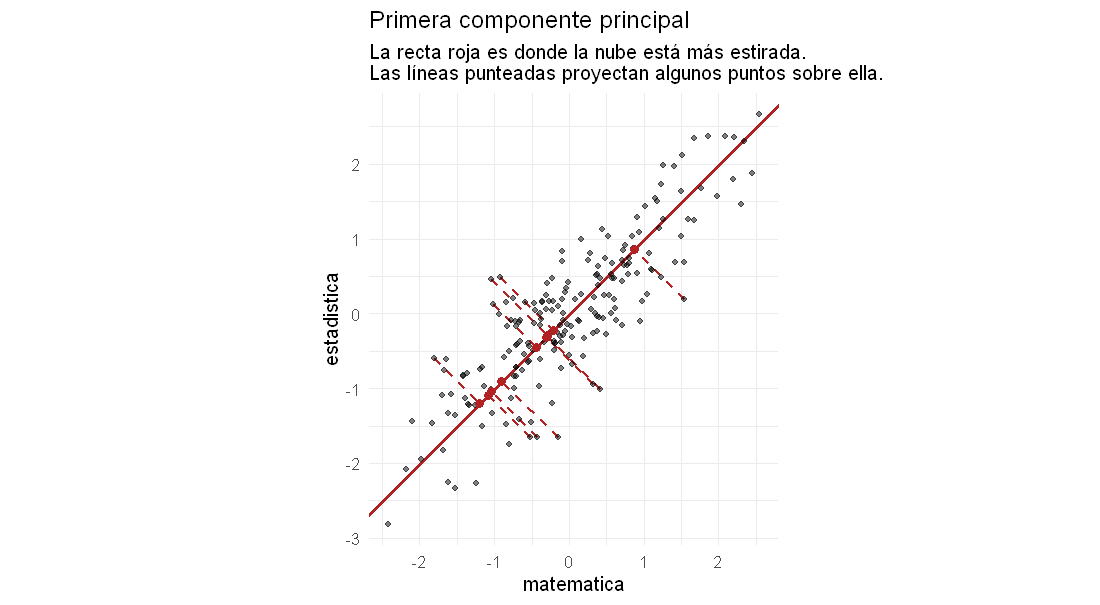

In [4]:
options(repr.plot.height = 5.5)
pca_notas <- prcomp(notas)
dir1 <- pca_notas$rotation[, 1]                   # dirección de la recta
proy <- tibble(pc1 = pca_notas$x[, 1]) |>         # posición sobre la recta
  mutate(x = pc1 * dir1[1], y = pc1 * dir1[2])

muestra <- order(abs(pca_notas$x[, 2]), decreasing = TRUE)[1:10]   # los 10 puntos más alejados de la recta
ggplot(notas, aes(matematica, estadistica)) +
  geom_abline(slope = dir1[2] / dir1[1], intercept = 0, color = "firebrick", linewidth = 1) +
  geom_segment(data = bind_cols(notas, proy)[muestra, ],
               aes(xend = x, yend = y), color = "firebrick", linetype = "dashed", linewidth = 0.7) +
  geom_point(alpha = 0.5) +
  geom_point(data = proy[muestra, ], aes(x, y), color = "firebrick", size = 2.5) +
  coord_equal() +
  labs(title = "Primera componente principal",
       subtitle = "La recta roja es donde la nube está más estirada.\nLas líneas punteadas proyectan algunos puntos sobre ella.")

In [5]:
summary(pca_notas)

Importance of components:
                         PC1     PC2
Standard deviation     1.360 0.38733
Proportion of Variance 0.925 0.07501
Cumulative Proportion  0.925 1.00000

> 💡 **Lectura.** La recta roja va en diagonal: la primera componente es básicamente el **promedio de las dos notas**. La salida de `summary()` dice que esa componente retiene el 92,5% de la varianza total (`Proportion of Variance` = 0,925). Si en lugar de dos números usamos uno solo (la posición sobre la recta), perdemos apenas el 7,5% de la información. Los puntos rojos sobre la recta son la versión resumida de los puntos unidos a ellos por las líneas punteadas: el largo de cada línea es lo que se pierde al resumir. La segunda componente, perpendicular a la primera, recoge lo que queda: si a alguien le va mejor en una materia que en la otra.

## 1.2 Lo mismo, con muchas variables

Con $p$ variables numéricas la idea es la misma. Las **componentes principales** son nuevas variables que cumplen tres condiciones:

1. Cada una es una **combinación lineal** de las variables originales: $\text{PC}_1 = a_1 x_1 + a_2 x_2 + \dots + a_p x_p$.
2. La primera tiene la **mayor varianza posible**; la segunda, la mayor varianza posible entre las que no están correlacionadas con la primera; y así sucesivamente.
3. Hay tantas componentes como variables, y entre todas conservan el 100% de la varianza.

La varianza de cada componente se llama **autovalor** ($\lambda_1 \geq \lambda_2 \geq \dots$). El **porcentaje de varianza explicada** de la componente $s$ es

$$\%_s = \frac{\lambda_s}{\sum_t \lambda_t} \times 100$$

Si las primeras dos o tres componentes juntan buena parte de la varianza, podemos describir los datos con esas pocas variables: graficarlos en un plano, interpretarlas, o usarlas como insumo de otro análisis (por ejemplo, un *clustering*). Este procedimiento se llama **análisis de componentes principales** (PCA).

## 1.3 ¿Y si las variables son categorías?

El PCA usa medias, varianzas y correlaciones. Con variables como "condición de actividad" (asalariado, desocupado, jubilado...) nada de eso tiene sentido: no existe el "promedio" entre asalariado y jubilado.

El **análisis de correspondencias múltiples (MCA)** resuelve esto en dos pasos:

1. Convierte cada categoría en una columna de ceros y unos (la **tabla disyuntiva**).
2. Hace sobre esa tabla algo muy parecido a un PCA, pero con una forma particular de medir distancias (la **distancia chi-cuadrado**) que tiene en cuenta cuán frecuente es cada categoría.

El resultado es el mismo tipo de objeto que en el PCA: unas pocas **dimensiones** numéricas que resumen la información, cada una con su autovalor y su porcentaje (que en MCA se llama **inercia** en lugar de varianza). La Parte 2 explica cada paso con un ejemplo chico.

# Parte 2. MCA: la teoría con un ejemplo chico

Ocho personas inventadas y tres variables categóricas. Es lo bastante chico como para ver todos los números, y tiene las mismas piezas que el caso real.

In [6]:
juguete <- tibble(
  condicion = c("Ocupado", "Ocupado", "Desocupado", "Ocupado",
                "Ocupado", "Inactivo", "Inactivo", "Ocupado"),
  educacion = c("Univ", "Sec", "Sec", "Univ", "Sec", "Sec", "Univ", "Univ"),
  salud     = c("Obra social", "Obra social", "Obra social", "Obra social",
                "Sin cobertura", "Sin cobertura", "Obra social", "Sin cobertura")) |>
  mutate(across(everything(), as.factor)) |>
  as.data.frame()
rownames(juguete) <- paste("Persona", 1:8)
juguete

,condicion,educacion,salud
,<fct>,<fct>,<fct>
Persona 1,Ocupado,Univ,Obra social
Persona 2,Ocupado,Sec,Obra social
Persona 3,Desocupado,Sec,Obra social
Persona 4,Ocupado,Univ,Obra social
Persona 5,Ocupado,Sec,Sin cobertura
Persona 6,Inactivo,Sec,Sin cobertura
Persona 7,Inactivo,Univ,Obra social
Persona 8,Ocupado,Univ,Sin cobertura


## 2.1 La tabla disyuntiva

El primer paso es pasar de $Q$ variables a $J$ columnas, una por **categoría**, con un 1 si la persona tiene esa categoría y un 0 si no. Esa matriz $Z$ (de $n$ filas por $J$ columnas) es la **tabla disyuntiva completa**. Cada fila tiene exactamente $Q$ unos, uno por variable.

In [7]:
Z <- tab.disjonctif(juguete)
Z

,Desocupado,Inactivo,Ocupado,Sec,Univ,Obra social,Sin cobertura
Persona 1,0,0,1,0,1,1,0
Persona 2,0,0,1,1,0,1,0
Persona 3,1,0,0,1,0,1,0
Persona 4,0,0,1,0,1,1,0
Persona 5,0,0,1,1,0,0,1
Persona 6,0,1,0,1,0,0,1
Persona 7,0,1,0,0,1,1,0
Persona 8,0,0,1,0,1,0,1


In [8]:
n  <- nrow(Z)          # personas
Q  <- ncol(juguete)    # variables
J  <- ncol(Z)          # categorías
nj <- colSums(Z)       # cuántas personas tienen cada categoría
fj <- nj / n           # frecuencia relativa de cada categoría
round(fj, 3)

Desocupado      Inactivo       Ocupado           Sec          Univ 
        0.125         0.250         0.625         0.500         0.500 
  Obra social Sin cobertura 
        0.625         0.375

> 💡 **Lectura.** $n = 8$ personas, $Q = 3$ variables y $J = 7$ categorías. Las frecuencias son muy distintas: "Desocupado" la tiene 1 de cada 8 personas ($f_j = 0{,}125$) y "Ocupado", 5 de cada 8 ($f_j = 0{,}625$). Esta diferencia va a ser clave en lo que sigue.

## 2.2 La distancia entre dos personas

¿Cuándo dos personas son "parecidas"? Cuando comparten categorías. El MCA mide la distancia entre dos personas $i$ e $i'$ con la **distancia chi-cuadrado**:

$$d^2(i, i') = \frac{1}{Q} \sum_{j=1}^{J} \frac{1}{f_j} \left(z_{ij} - z_{i'j}\right)^2$$

Se suman las categorías en las que las dos personas difieren ($z_{ij} - z_{i'j} = \pm 1$), pero cada diferencia se **divide por la frecuencia de la categoría**. Diferir en una categoría rara pesa mucho más que diferir en una común. La intuición: compartir una característica poco frecuente dice mucho de dos personas; compartir una que tiene casi todo el mundo, dice poco.

In [9]:
dist_chi2 <- function(i, k) sum((Z[i, ] - Z[k, ])^2 / fj) / Q

dist_chi2(1, 2)   # difieren solo en educación (Univ vs Sec)
dist_chi2(2, 3)   # difieren solo en condición (Ocupado vs Desocupado)

[1] 1.333333

[1] 3.2

> 💡 **Lectura.** Las personas 1 y 2 difieren solo en educación: Univ y Sec tienen 4 personas cada una, así que $d^2 = \frac{1}{3}\left(\frac{1}{0{,}5} + \frac{1}{0{,}5}\right) = 1{,}33$. Las personas 2 y 3 también difieren en **una sola** variable, pero una de las categorías involucradas es "Desocupado", que es rara: $d^2 = \frac{1}{3}\left(\frac{1}{0{,}625} + \frac{1}{0{,}125}\right) = 3{,}2$, más del doble. Para el MCA, la persona desocupada es "más distinta" que la universitaria.

## 2.3 Las categorías y la inercia

En el MCA las **categorías también son puntos** del mapa. Cada categoría se ubica en el **promedio de las personas que la tienen** (su *baricentro*), y el centro del mapa (el origen) es el perfil promedio de todas las personas. Su distancia al origen es

$$d^2(j, O) = \frac{1}{f_j} - 1$$

Las categorías raras quedan **lejos del origen** y las frecuentes, cerca. La **inercia** mide cuánto se aparta la nube de puntos de su centro (es el equivalente de la varianza total del PCA). La inercia de cada categoría es su peso ($f_j / Q$) por su distancia al cuadrado:

$$I(j) = \frac{f_j}{Q} \cdot \left(\frac{1}{f_j} - 1\right) = \frac{1 - f_j}{Q}$$

Si se suman todas las categorías, la **inercia total** depende solo de cuántas variables y categorías hay, no de los datos:

$$I_{\text{total}} = \sum_j \frac{1 - f_j}{Q} = \frac{J}{Q} - 1$$

In [10]:
tibble(categoria     = names(fj),
       f_j           = round(fj, 3),
       dist2_origen  = round(1 / fj - 1, 2),
       inercia       = round((1 - fj) / Q, 3))

J / Q - 1   # inercia total

categoria,f_j,dist2_origen,inercia
<chr>,<dbl>,<dbl>,<dbl>
Desocupado,0.125,7.00,0.292
Inactivo,0.250,3.00,0.250
Ocupado,0.625,0.60,0.125
Sec,0.500,1.00,0.167
Univ,0.500,1.00,0.167
Obra social,0.625,0.60,0.125
Sin cobertura,0.375,1.67,0.208


[1] 1.333333

> 💡 **Lectura.** "Desocupado" está a distancia al cuadrado 7 del origen; "Ocupado", a 0,6. Pero la inercia de "Desocupado" (0,29) no es tanto mayor que la de "Ocupado" (0,125), porque la distancia se multiplica por el peso de la categoría, que es chico. La inercia total es $7/3 - 1 = 1{,}33$. Dos consecuencias prácticas: (1) una variable con muchas categorías aporta más inercia que una con pocas (la inercia de la variable $q$ es $(K_q - 1)/Q$, con $K_q$ su cantidad de categorías); (2) una categoría con muy pocos casos queda tan lejos del origen que puede "robarse" una dimensión entera.

## 2.4 Qué hace el MCA

El MCA busca, como el PCA, las direcciones en las que la nube de personas está más estirada, pero midiendo con la distancia chi-cuadrado. Cada dimensión $s$ tiene:

- Un **autovalor** $\lambda_s$: la inercia que resume esa dimensión. El porcentaje de inercia es $\lambda_s / I_{\text{total}}$.
- **Coordenadas de las personas** $F_s(i)$: la posición de cada persona sobre la dimensión.
- **Coordenadas de las categorías** $G_s(j)$: la posición de cada categoría.

Personas y categorías se relacionan por las **fórmulas de baricentro**, que son las que permiten leer el mapa:

$$G_s(j) = \frac{1}{\sqrt{\lambda_s}} \cdot \underbrace{\text{promedio de } F_s(i) \text{ entre quienes tienen } j}_{\text{centro de las personas con la categoría}}
\qquad\qquad
F_s(i) = \frac{1}{\sqrt{\lambda_s}} \cdot \underbrace{\frac{1}{Q} \sum_{j \in i} G_s(j)}_{\text{promedio de sus categorías}}$$

Una categoría está donde están las personas que la tienen; una persona está en el promedio de sus categorías. Por eso, si dos categorías quedan cerca en el mapa, es porque **las tienen las mismas personas**.

Hay $J - Q$ dimensiones (acá, $7 - 3 = 4$). Corremos el MCA con `FactoMineR::MCA()`:

In [11]:
mca_jug <- MCA(juguete, graph = FALSE)
mca_jug$eig

,eigenvalue,percentage of variance,cumulative percentage of variance
dim 1,0.4625112,34.688339,34.68834
dim 2,0.4278081,32.085611,66.77395
dim 3,0.3170743,23.780574,90.55452
dim 4,0.1259397,9.445476,100.00000


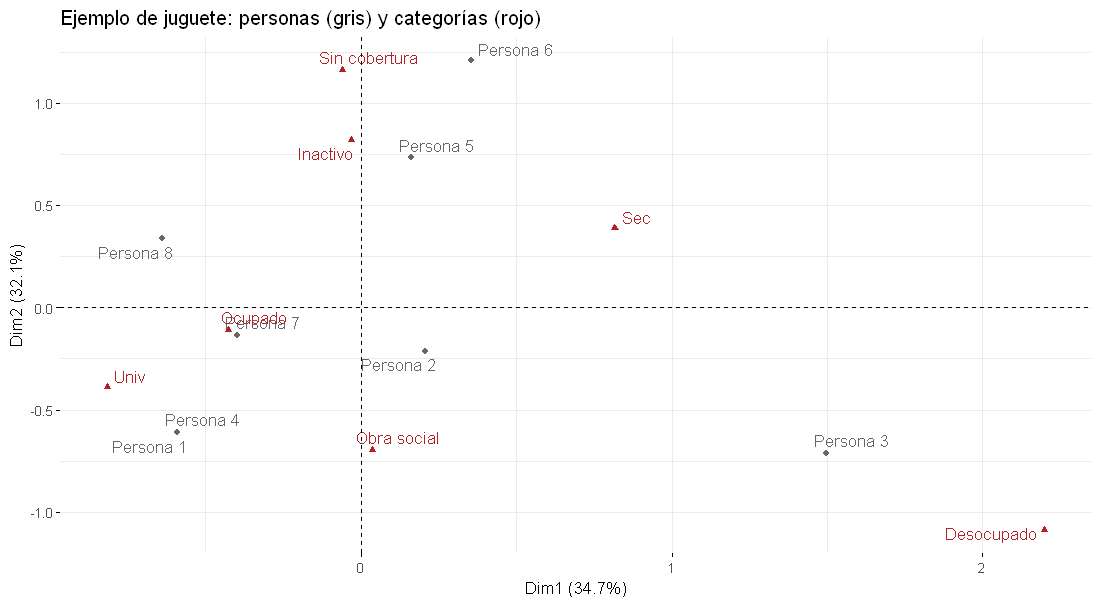

In [12]:
options(repr.plot.height = 5.5)
fviz_mca_biplot(mca_jug, repel = TRUE, col.ind = "gray40", col.var = "firebrick",
                title = "Ejemplo de juguete: personas (gris) y categorías (rojo)")

> 💡 **Lectura.** Los cuatro autovalores suman 1,33, la inercia total que calculamos a mano. Las dos primeras dimensiones resumen el 35% y el 32%. En el mapa, "Desocupado" queda lejos de todo, abajo a la derecha, cerca de la Persona 3, la única que tiene esa categoría: es el efecto de las categorías raras. "Sec" y "Univ" quedan en lados opuestos del origen, a la misma distancia (cada una tiene la mitad de las personas). Las personas 1 y 4 tienen exactamente las mismas respuestas y caen en el mismo punto.

Comprobamos la fórmula de baricentro con "Sec" en la Dim 1. La tienen las personas 2, 3, 5 y 6:

In [13]:
lambda1 <- mca_jug$eig[1, 1]
con_sec <- juguete$educacion == "Sec"
mean(mca_jug$ind$coord[con_sec, 1]) / sqrt(lambda1)   # a mano: promedio de esas personas / raíz del autovalor
mca_jug$var$coord["Sec", 1]                          # lo que da MCA()

[1] 0.8163868

[1] 0.8163868

> 💡 **Lectura.** Las dos cuentas dan 0,816: la categoría "Sec" está en el promedio de las cuatro personas que la tienen, estirado por $1/\sqrt{\lambda_1}$. Por eso, en el mapa, la categoría queda del mismo lado que sus personas pero más lejos del origen.

## 2.5 Las herramientas para interpretar

Un MCA real tiene decenas de categorías y miles de personas. Para leerlo se usan cinco indicadores. Conviene tener esta tabla a mano durante toda la Parte 3.

| Indicador | Fórmula | Qué responde | Cómo se usa |
|:--|:--|:--|:--|
| **% de inercia** | $\lambda_s / I_{\text{total}}$ | ¿Cuánta información resume la dimensión? | Decidir cuántas dimensiones mirar |
| **Contribución** (`contrib`) | $\text{ctr}_s(j) = \dfrac{(f_j/Q)\, G_s(j)^2}{\lambda_s} \times 100$ | ¿Qué categorías **construyen** la dimensión? Suma 100% en cada dimensión | **Nombrar** la dimensión: mirar las que superan el promedio, $100/J$ |
| **cos²** | $\cos^2_s(j) = \dfrac{G_s(j)^2}{1/f_j - 1}$ | ¿Qué parte de la distancia de la categoría al origen está en esta dimensión? Va de 0 a 1 | Saber si la posición de una categoría en el mapa es confiable |
| **eta²** (`eta2`) | $\eta^2_s(q)$ = $R^2$ de regresar $F_s$ contra la variable $q$ | ¿Qué **variables** (no categorías) están ligadas a la dimensión? | Resumen por variable. Cumple $\lambda_s = \frac{1}{Q}\sum_q \eta^2_s(q)$ |
| **v.test** | $G_s(j)\sqrt{\dfrac{n_j (n-1)}{n - n_j}}$ | ¿La categoría se aparta del origen más de lo que daría el azar? | Sobre todo para las **suplementarias**. $\lvert v \rvert > 2$ es significativo al 5% |

Dos ideas más:

- **Variables activas y suplementarias.** Las *activas* construyen las dimensiones. Las *suplementarias* no participan del cálculo: se ubican después en el mapa (con la fórmula de baricentro) para ayudar a interpretarlo. Si una suplementaria se ordena sobre una dimensión, es una validación "externa" de lo que creemos que mide esa dimensión.
- **Los % de inercia son bajos por construcción.** Al pasar a la tabla disyuntiva aparecen muchas dimensiones que solo reflejan la codificación 0/1. Por eso un 15% en la primera dimensión de un MCA no es "poco". La **corrección de Benzécri** recalcula los porcentajes contando solo las dimensiones con $\lambda_s > 1/Q$ (el autovalor promedio):

$$\tilde\lambda_s = \left[\frac{Q}{Q-1}\left(\lambda_s - \frac{1}{Q}\right)\right]^2 \quad \text{si } \lambda_s > \frac{1}{Q}$$

> ⚠️ **Atención.** No comparar nunca los % de inercia de un MCA con los % de varianza de un PCA: están en escalas distintas. Un PCA con 25% en la primera componente es flojo; un MCA con 25% en la primera dimensión es muy bueno.

# Parte 3. El MCA con la EPH

## 3.1 Armar las variables categóricas

El MCA trabaja con **factores**. La decisión más importante del análisis no es el algoritmo: es **qué variables entran y cómo se agrupan sus categorías**. Trabajamos con las personas de 18 años y más que son ocupadas, desocupadas o inactivas.

Las variables **activas** (las que van a definir qué personas se parecen) son seis:

| Variable | Categorías | Variables EPH |
|:--|:--|:--|
| `condicion` | Asalariado registrado, no registrado, cuenta propia / patrón, desocupado, jubilado, estudiante, otro inactivo | `ESTADO`, `CAT_OCUP`, `PP07H` (descuento jubilatorio), `V2_01_M` (cobra jubilación), `CH10` (asiste a un establecimiento educativo) |
| `educacion` | Hasta secundario incompleto, secundario completo, universitario completo | `NIVEL_ED` |
| `salud` | Obra social / prepaga, sin cobertura / plan estatal | `CH08` |
| `edad` | 18 a 29, 30 a 44, 45 a 64, 65 y más | `CH06` |
| `est_civil` | Unido / casado, separado / viudo, soltero | `CH07` |
| `parentesco` | Jefe/a, cónyuge, hijo/a, otro familiar | `CH03` |

Las **suplementarias** (para interpretar, no para construir) son sexo, región, quintil de ingreso per cápita familiar y la edad en años.

In [14]:
pers <- eph |>
  filter(CH06 >= 18, ESTADO %in% 1:3) |>
  transmute(
    # --- activas ---
    condicion = case_when(
      ESTADO == 1 & CAT_OCUP == 3 & PP07H == 1 ~ "Asal. registrado",
      ESTADO == 1 & CAT_OCUP == 3 & PP07H == 2 ~ "Asal. no registrado",
      ESTADO == 1 & CAT_OCUP %in% 1:2          ~ "Cuenta propia / patrón",
      ESTADO == 2                              ~ "Desocupado",
      ESTADO == 3 & V2_01_M > 0                ~ "Jubilado / pensionado",
      ESTADO == 3 & CH10 == 1                  ~ "Estudiante",
      ESTADO == 3                              ~ "Otro inactivo"),
    educacion = case_when(NIVEL_ED %in% c(1, 2, 3, 7) ~ "Hasta sec. incompleto",
                          NIVEL_ED %in% c(4, 5)       ~ "Sec. completo",
                          NIVEL_ED == 6               ~ "Univ. completo"),
    salud = case_when(CH08 %in% c(1, 2, 12, 13, 23, 123) ~ "Obra social / prepaga",
                      CH08 %in% c(3, 4)                  ~ "Sin cobertura / plan estatal"),
    edad = cut(CH06, c(-Inf, 29, 44, 64, Inf),
               labels = c("18 a 29", "30 a 44", "45 a 64", "65 y más")),
    est_civil = case_when(CH07 %in% 1:2 ~ "Unido / casado",
                          CH07 %in% 3:4 ~ "Separado / viudo",
                          CH07 == 5     ~ "Soltero"),
    parentesco = case_when(CH03 == 1 ~ "Jefe/a",
                           CH03 == 2 ~ "Cónyuge",
                           CH03 == 3 ~ "Hijo/a",
                           TRUE      ~ "Otro familiar"),
    # --- suplementarias ---
    sexo   = if_else(CH04 == 1, "Varón", "Mujer"),
    region = factor(REGION, c(1, 40, 41, 42, 43, 44),
                    c("GBA", "NOA", "NEA", "Cuyo", "Pampeana", "Patagonia")),
    quintil_ipcf = if_else(DECCFR %in% 1:10,
                           paste0("Quintil ", ceiling(DECCFR / 2)), "Sin dato"),
    edad_num = CH06,
    PONDERA
  )

colSums(is.na(pers))    # ¿cuántos casos quedan sin categoría?

condicion    educacion        salud         edad    est_civil   parentesco 
          64            0           36            0            0            0 
        sexo       region quintil_ipcf     edad_num      PONDERA 
           0            0            0            0            0

> 💡 **Lectura.** Quedan sin categoría 64 personas en `condicion` (son trabajadores familiares sin remuneración, `CAT_OCUP` = 4, que no entran en ninguna de las siete categorías) y 36 en `salud` (no saben o no responden, `CH08` = 9). Son menos del 0,3% de los casos: los sacamos.

In [15]:
pers <- pers |>
  drop_na() |>
  mutate(across(condicion:quintil_ipcf, as.factor))
nrow(pers)

[1] 33375

## 3.2 Frecuencias: buscar categorías raras

Antes de correr el MCA hay que mirar cuántos casos tiene cada categoría. Como vimos en la Parte 2, una categoría con muy pocos casos queda lejísimos del origen y puede quedarse con una dimensión entera, que termina describiendo a un 2% de las personas. La regla práctica es que ninguna categoría activa tenga menos del 3-5% de los casos.

In [16]:
pers |>
  select(condicion:parentesco) |>
  pivot_longer(everything(), names_to = "variable", values_to = "categoria") |>
  count(variable, categoria) |>
  group_by(variable) |>
  mutate(pct = round(100 * n / sum(n), 1)) |>
  ungroup()

variable,categoria,n,pct
<chr>,<fct>,<int>,<dbl>
condicion,Asal. no registrado,5192,15.6
condicion,Asal. registrado,8690,26.0
condicion,Cuenta propia / patrón,5538,16.6
condicion,Desocupado,1395,4.2
condicion,Estudiante,2191,6.6
condicion,Jubilado / pensionado,3957,11.9
condicion,Otro inactivo,6412,19.2
edad,18 a 29,7977,23.9
edad,30 a 44,8990,26.9


> 💡 **Lectura.** Ninguna categoría queda por debajo del 4%. Esto no es casualidad: varias categorías ya están **agrupadas** en el código de la sección 3.1, porque solas serían raras. "Prepaga / mutual" sola tiene alrededor del 3% de los casos y va con obra social. El "plan estatal" (1,5%) va con "sin cobertura". "Patrón" va con "cuenta propia". Separado y viudo van juntos.

> ⚠️ **Atención.** Agrupar no es juntar cualquier cosa con cualquier cosa hasta que las frecuencias den bien: la nueva categoría tiene que tener **sentido**. Obra social y prepaga son dos formas de cobertura contributiva o pagada. El plan estatal y no tener cobertura significan, en la práctica, atenderse en el sistema público. Juntar prepaga con plan estatal también daría una categoría "grande", pero mezclaría situaciones opuestas y el mapa no se podría interpretar.

## 3.3 Correr el MCA

`MCA()` recibe un data frame de factores y estos argumentos:

- `quali.sup`: posiciones de las columnas **suplementarias categóricas** (sexo, región, quintil).
- `quanti.sup`: posiciones de las **suplementarias numéricas** (la edad en años). Para estas, el MCA informa su correlación con cada dimensión.
- `row.w`: el **ponderador** de cada persona. La EPH es una muestra: cada persona representa a `PONDERA` personas de la población. Ponderando, el mapa describe a la población y no a la muestra.
- `ncp`: cuántas dimensiones guardar (pedimos 10).

In [17]:
base_mca <- pers |>
  select(condicion, educacion, salud, edad, est_civil, parentesco,  # 1-6 activas
         sexo, region, quintil_ipcf,                                # 7-9 suplementarias
         edad_num) |>                                               # 10 numérica suplementaria
  as.data.frame()

peso <- pers$PONDERA / mean(pers$PONDERA)   # ponderador reescalado: suma la cantidad de casos

res_mca <- MCA(base_mca, ncp = 10, quali.sup = 7:9, quanti.sup = 10,
               row.w = peso, graph = FALSE)
res_mca

**Results of the Multiple Correspondence Analysis (MCA)**
The analysis was performed on 33375 individuals, described by 10 variables
*The results are available in the following objects:

   name                description                                           
1  "$eig"              "eigenvalues"                                         
2  "$var"              "results for the variables"                           
3  "$var$coord"        "coord. of the categories"                            
4  "$var$cos2"         "cos2 for the categories"                             
5  "$var$contrib"      "contributions of the categories"                     
6  "$var$v.test"       "v-test for the categories"                           
7  "$var$eta2"         "coord. of variables"                                 
8  "$ind"              "results for the individuals"                         
9  "$ind$coord"        "coord. for the individuals"                          
10 "$ind$cos2"         "cos2 for 

> 💡 **Lectura.** `res_mca` es una lista. Las partes que vamos a usar son `$eig` (autovalores), `$var` (coordenadas, contribuciones, cos² y eta² de las categorías activas), `$quali.sup` y `$quanti.sup` (las suplementarias) e `$ind` (las coordenadas de cada persona).

> ⚠️ **Atención.** El ponderador se **reescala** para que su promedio sea 1 (y su suma, la cantidad de casos de la muestra). Las coordenadas son las mismas que con `PONDERA` crudo, pero los tests no. Si los pesos suman 21 millones, `MCA()` calcula los v.test como si hubiera 21 millones de observaciones: el v.test de "Mujer" en la Dim 1 pasa de −13,6 a −348. Siempre que una función use los pesos para un test, conviene reescalarlos así.

## 3.4 ¿Cuántas dimensiones mirar?

In [18]:
round(res_mca$eig[1:10, ], 2)

,eigenvalue,percentage of variance,cumulative percentage of variance
dim 1,0.47,16.58,16.58
dim 2,0.32,11.18,27.76
dim 3,0.27,9.59,37.35
dim 4,0.21,7.41,44.76
dim 5,0.18,6.33,51.09
dim 6,0.17,6.13,57.21
dim 7,0.17,5.92,63.13
dim 8,0.16,5.65,68.78
dim 9,0.15,5.31,74.09
dim 10,0.15,5.14,79.24


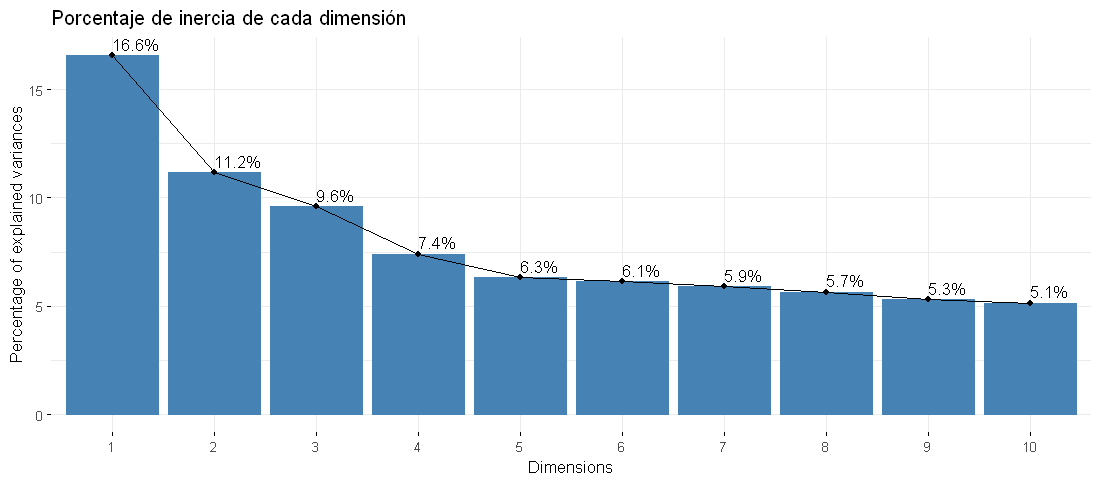

In [19]:
options(repr.plot.height = 4.4)
fviz_screeplot(res_mca, addlabels = TRUE, ncp = 10,
               title = "Porcentaje de inercia de cada dimensión")

> 💡 **Lectura.** La Dim 1 resume el 16,6% de la inercia, la Dim 2 el 11,2% y la Dim 3 el 9,6%. A partir de la Dim 4 (7,4%) los porcentajes bajan despacio: no hay un "codo" nítido. Las primeras 5 dimensiones suman el 51%. La inercia total es $J/Q - 1 = 23/6 - 1 = 2{,}83$, y la columna `eigenvalue` muestra cuánto de eso resume cada dimensión (0,47 la primera).

Como los porcentajes crudos están "diluidos" por la codificación 0/1, aplicamos la corrección de Benzécri. Con $Q = 6$ variables, el umbral es $1/Q = 0{,}167$:

In [20]:
Q_eph  <- 6
lambda <- res_mca$eig[, 1]
benzecri <- ifelse(lambda > 1 / Q_eph, ((Q_eph / (Q_eph - 1)) * (lambda - 1 / Q_eph))^2, 0)

tibble(dimension     = 1:8,
       autovalor     = round(lambda[1:8], 3),
       pct_crudo     = round(res_mca$eig[1:8, 2], 1),
       pct_benzecri  = round(100 * benzecri[1:8] / sum(benzecri), 1))

dimension,autovalor,pct_crudo,pct_benzecri
<int>,<dbl>,<dbl>,<dbl>
1,0.470,16.6,72.0
2,0.317,11.2,17.7
3,0.272,9.6,8.7
4,0.210,7.4,1.5
5,0.179,6.3,0.1
6,0.174,6.1,0.0
7,0.168,5.9,0.0
8,0.160,5.7,0.0


> 💡 **Lectura.** Con la corrección, la Dim 1 resume el 72% de la inercia "real", la Dim 2 el 18% y la Dim 3 el 9%: entre las tres, el 98%. Las Dim 5 a 7 tienen autovalores apenas por encima de 0,167 y su inercia corregida es casi nula. Conclusión: las **tres primeras dimensiones** son la estructura principal y las vamos a interpretar en detalle. La 4 y la 5 tienen algo de información (lo vemos en la sección 3.8) y las usaremos en el k-means.

## 3.5 Un mapa de las categorías

El gráfico de categorías ubica cada categoría activa según sus coordenadas en las Dim 1 y 2. El color indica la **contribución** al plano.

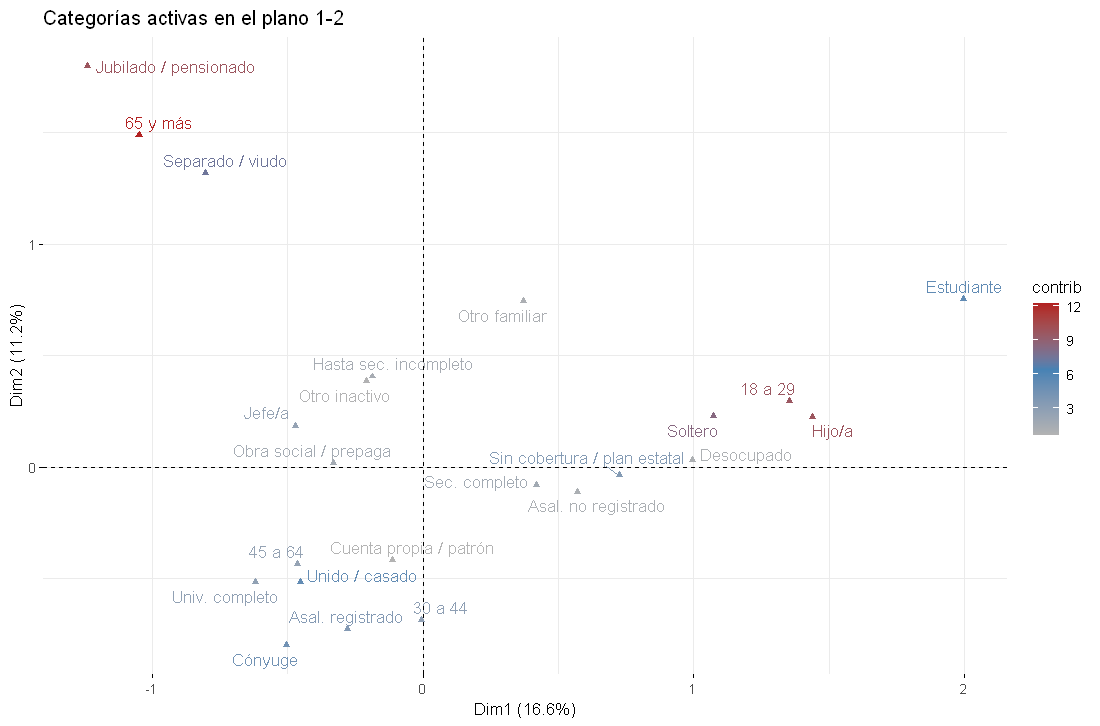

In [21]:
options(repr.plot.height = 6.6)
fviz_mca_var(res_mca, choice = "var.cat", invisible = "quali.sup", repel = TRUE,
             col.var = "contrib", gradient.cols = c("gray70", "steelblue", "firebrick"),
             title = "Categorías activas en el plano 1-2")

Cómo se lee este mapa:

- **El origen** es el perfil promedio. Una categoría cerca del origen se parece al promedio en ese plano, o está bien representada en otras dimensiones (hay que mirar el cos²).
- **Dos categorías cercanas** son categorías que tienen las mismas personas.
- **Categorías de lados opuestos** del origen sobre un eje son perfiles opuestos en esa dimensión.
- **El signo es arbitrario**: si se corre en otra computadora, una dimensión puede salir "dada vuelta". Lo que importa es qué categorías están de cada lado, no si es positivo o negativo.

Para leer cada dimensión por separado usamos una tabla con las categorías ordenadas por contribución. Las que superan la contribución promedio ($100 / J = 100/23 = 4{,}3\%$) son las que **construyen** la dimensión y las que hay que usar para nombrarla. La columna `lado` dice de qué lado del origen quedan.

In [22]:
tabla_dim <- function(res, s, top = 8) {
  tibble(categoria = rownames(res$var$coord),
         coord     = round(res$var$coord[, s], 2),
         contrib   = round(res$var$contrib[, s], 1),
         cos2      = round(res$var$cos2[, s], 2)) |>
    arrange(desc(contrib)) |>
    head(top) |>
    mutate(lado = if_else(coord > 0, "+", "−"))
}

## 3.6 Dimensión 1: la juventud

In [23]:
tabla_dim(res_mca, 1)

categoria,coord,contrib,cos2,lado
<chr>,<dbl>,<dbl>,<dbl>,<chr>
Hijo/a,1.44,16.0,0.58,+
18 a 29,1.35,15.4,0.57,+
Soltero,1.07,13.5,0.57,+
Estudiante,2.00,7.9,0.23,+
65 y más,-1.05,6.8,0.23,−
Sin cobertura / plan estatal,0.72,5.9,0.24,+
Jubilado / pensionado,-1.24,5.3,0.16,−
Unido / casado,-0.45,3.8,0.23,−


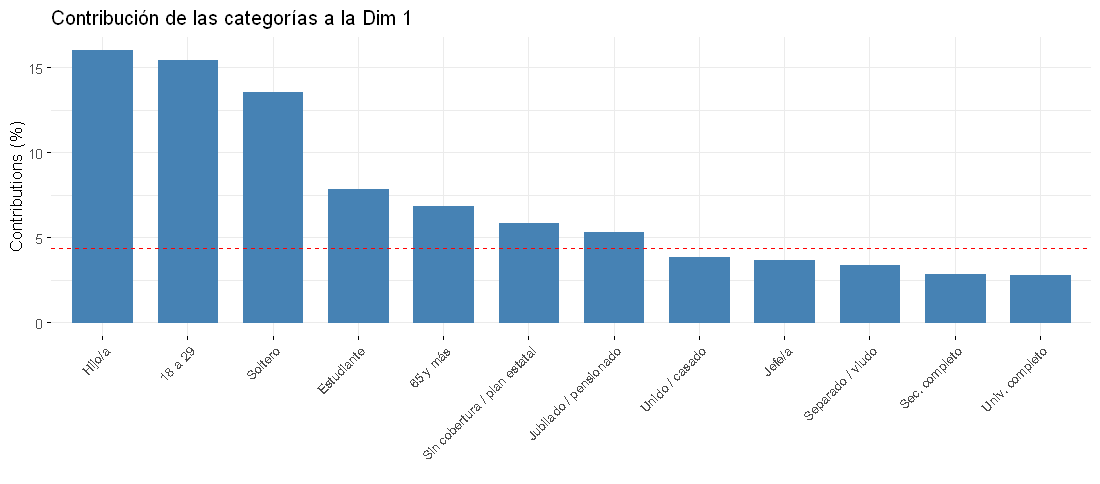

In [24]:
options(repr.plot.height = 4.4)
fviz_contrib(res_mca, choice = "var", axes = 1, top = 12,
             title = "Contribución de las categorías a la Dim 1")

> 💡 **Lectura (el caso).** Las categorías que más construyen la Dim 1 son hijo/a (16%), 18 a 29 años (15%), soltero (13,5%) y estudiante (8%), todas del lado **positivo**. Del lado negativo están 65 y más (7%) y jubilado (5%). La línea punteada roja del gráfico es la contribución promedio (4,3%). La Dim 1 separa a los **jóvenes que viven con sus padres** (solteros, estudiantes o buscando trabajo) de los adultos y mayores: es el **ciclo de vida, en su etapa joven**.
>
> **Lectura (la teoría).** Que una categoría tenga contribución alta y cos² alto (hijo/a: 0,58) quiere decir que construye el eje *y* que casi toda su distancia al origen está en este eje. Las tres categorías que más contribuyen tienen cos² de 0,57-0,58: la Dim 1 es, sobre todo, la historia de ellas.

## 3.7 Dimensión 2: la vejez

In [25]:
tabla_dim(res_mca, 2)

categoria,coord,contrib,cos2,lado
<chr>,<dbl>,<dbl>,<dbl>,<chr>
65 y más,1.49,20.3,0.47,+
Jubilado / pensionado,1.80,16.5,0.35,+
Separado / viudo,1.32,13.5,0.30,+
Cónyuge,-0.80,8.1,0.20,−
Asal. registrado,-0.73,7.6,0.20,−
30 a 44,-0.69,7.3,0.20,−
Unido / casado,-0.52,7.3,0.29,−
Hasta sec. incompleto,0.41,3.0,0.09,+


> 💡 **Lectura (el caso).** Del lado positivo, 65 y más (20%), jubilado / pensionado (16,5%) y separado / viudo (13,5%). Del lado negativo, cónyuge (8%), asalariado registrado (7,6%), 30 a 44 años (7%) y unido / casado (7%). La Dim 2 separa la **vejez** (jubilados, muchos viudos) de la **adultez activa** (parejas de 30 a 44 años con trabajo formal).
>
> **Lectura (la teoría).** En el mapa del plano 1-2, los jubilados quedan arriba a la izquierda: negativos en la Dim 1 (no son jóvenes) y muy positivos en la Dim 2. Las dos primeras dimensiones juntas describen el **ciclo de vida** en tres etapas: jóvenes (derecha), adultos activos (abajo a la izquierda) y mayores (arriba a la izquierda).

## 3.8 Dimensión 3: formalidad y vulnerabilidad

In [26]:
tabla_dim(res_mca, 3)

categoria,coord,contrib,cos2,lado
<chr>,<dbl>,<dbl>,<dbl>,<chr>
Sin cobertura / plan estatal,1.00,19.4,0.46,+
Asal. registrado,-1.00,16.8,0.38,−
Hasta sec. incompleto,0.78,12.7,0.31,+
Obra social / prepaga,-0.46,8.9,0.46,−
Univ. completo,-0.79,7.7,0.16,−
Asal. no registrado,0.77,6.1,0.12,+
Otro inactivo,0.69,5.4,0.11,+
Estudiante,-1.07,3.9,0.07,−


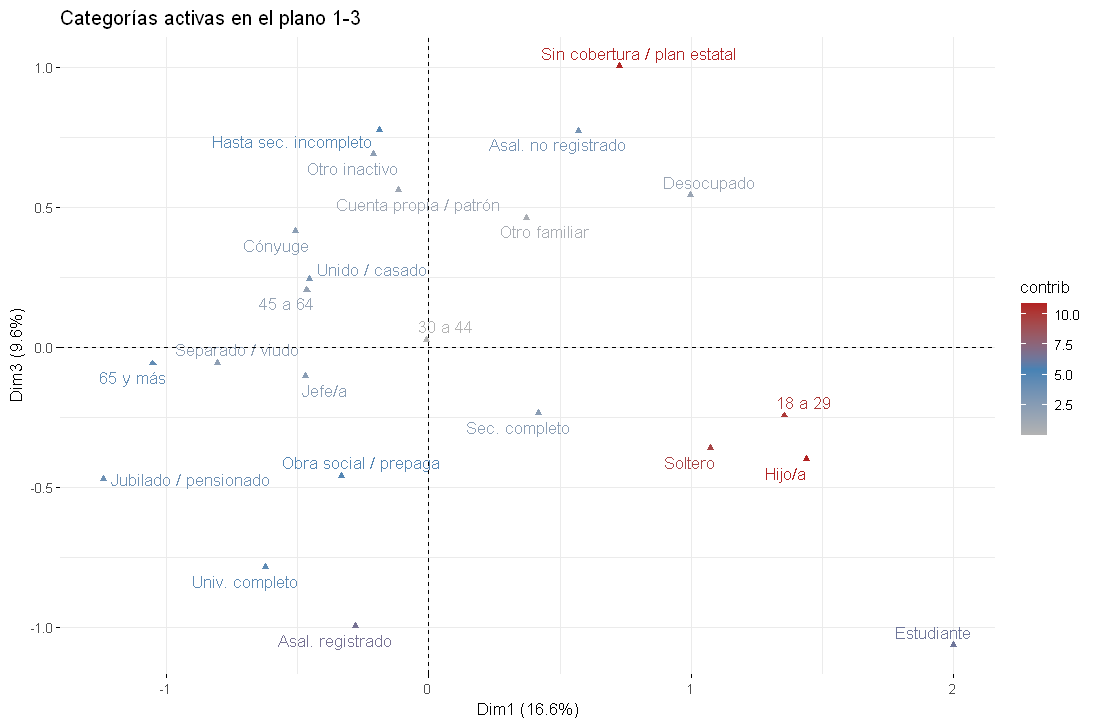

In [27]:
options(repr.plot.height = 6.6)
fviz_mca_var(res_mca, choice = "var.cat", invisible = "quali.sup", axes = c(1, 3),
             repel = TRUE, col.var = "contrib",
             gradient.cols = c("gray70", "steelblue", "firebrick"),
             title = "Categorías activas en el plano 1-3")

> 💡 **Lectura (el caso).** Esta dimensión ya no habla de la edad. Del lado positivo, sin cobertura / plan estatal (19%), hasta secundario incompleto (13%) y asalariado no registrado (6%). Del lado negativo, asalariado registrado (17%), obra social (9%) y universitario completo (8%). La Dim 3 es un eje de **formalidad versus vulnerabilidad**: trabajo registrado, cobertura y educación de un lado; informalidad, sin cobertura y educación baja del otro.
>
> **Lectura (la teoría).** Fijate que la Dim 3 explica solo el 9,6% de la inercia y, sin embargo, es la que más nos interesa para un análisis socioeconómico. El orden de las dimensiones dice cuánta inercia resumen, no cuán importantes son para nuestra pregunta. Si solo miráramos el plano 1-2, nos perderíamos esta dimensión.

## 3.9 Dimensiones 4 y 5, en breve

El k-means de la Parte 5 va a usar las primeras 5 dimensiones, así que necesitamos saber también qué son la 4 y la 5:

In [28]:
tabla_dim(res_mca, 4, top = 5)
tabla_dim(res_mca, 5, top = 5)

categoria,coord,contrib,cos2,lado
<chr>,<dbl>,<dbl>,<dbl>,<chr>
Cónyuge,1.09,22.8,0.38,+
Jefe/a,-0.66,16.1,0.38,−
Otro inactivo,1.02,15.5,0.24,+
Separado / viudo,-0.86,8.6,0.13,−
Cuenta propia / patrón,-0.64,5.6,0.09,−


categoria,coord,contrib,cos2,lado
<chr>,<dbl>,<dbl>,<dbl>,<chr>
45 a 64,-1.02,28.5,0.43,−
30 a 44,0.97,25.5,0.39,+
Asal. no registrado,0.96,14.2,0.18,+
Cuenta propia / patrón,-0.92,13.6,0.18,−
Estudiante,-1.18,7.1,0.08,−


> 💡 **Lectura.** La **Dim 4** es la **posición en el hogar**: cónyuge (23%) y "otro inactivo" (15,5%, en su mayoría personas dedicadas a las tareas del hogar) de un lado, jefe/a (16%) del otro. La **Dim 5** separa a los adultos de **30 a 44** años de los de **45 a 64**, y con ellos a los asalariados no registrados de los cuentapropistas (cada uno está del mismo lado que el tramo de edad donde es más frecuente).

## 3.10 Variables, no categorías: eta²

La contribución y el cos² se calculan por categoría. Para ver qué **variables** están ligadas a cada dimensión se usa eta² (la proporción de la varianza de la coordenada que explica la variable, como un $R^2$).

In [29]:
round(res_mca$var$eta2[, 1:5], 2)

,Dim 1,Dim 2,Dim 3,Dim 4,Dim 5
condicion,0.51,0.55,0.61,0.41,0.43
educacion,0.17,0.11,0.36,0.01,0.02
salud,0.24,0.00,0.46,0.04,0.00
edad,0.69,0.60,0.03,0.12,0.62
est_civil,0.58,0.41,0.07,0.17,0.00
parentesco,0.63,0.22,0.10,0.50,0.01


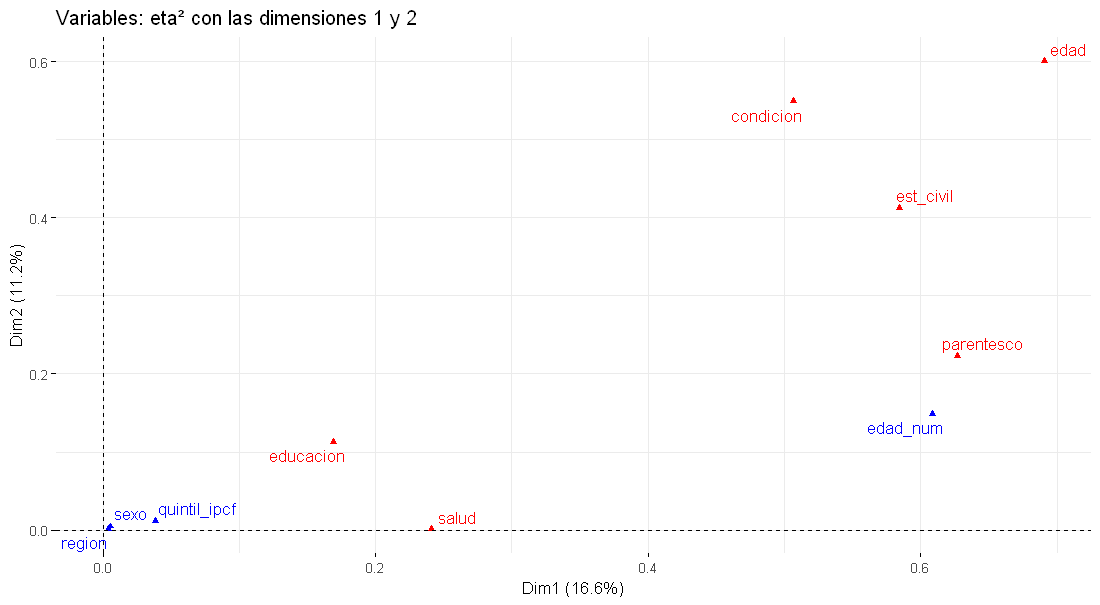

In [30]:
options(repr.plot.height = 5.5)
fviz_mca_var(res_mca, choice = "mca.cor", repel = TRUE,
             title = "Variables: eta² con las dimensiones 1 y 2")

> 💡 **Lectura.** Edad (0,69), parentesco (0,63) y estado civil (0,58) son las variables más ligadas a la Dim 1; edad (0,60) y condición (0,55) a la Dim 2; condición (0,61), salud (0,46) y educación (0,36) a la Dim 3. Salud casi no tiene relación con las Dim 1 y 2 (0,24 y 0,00): la cobertura no depende tanto de la etapa de la vida, sino de la formalidad. Si se promedian los eta² de las 6 variables en una dimensión, se obtiene su autovalor (por ejemplo, 0,47 en la Dim 1).

> ⚠️ **Atención.** `condicion` tiene eta² alto en **todas** las dimensiones (entre 0,41 y 0,61). No es que "lo explique todo": tiene 7 categorías, y una variable con muchas categorías tiene más inercia ($(K_q - 1)/Q$) y más margen para relacionarse con varios ejes. Al comparar eta² entre variables, tener en cuenta cuántas categorías tiene cada una.

## 3.11 La calidad de representación: cos²

Un cos² bajo en el plano que estamos mirando significa que la posición de esa categoría en el mapa **no es confiable**: su diferencia con el promedio está en otras dimensiones.

In [31]:
cos2_planos <- tibble(categoria = rownames(res_mca$var$cos2),
                      plano_12  = round(res_mca$var$cos2[, 1] + res_mca$var$cos2[, 2], 2),
                      plano_13  = round(res_mca$var$cos2[, 1] + res_mca$var$cos2[, 3], 2)) |>
  arrange(plano_12)
cos2_planos

categoria,plano_12,plano_13
<chr>,<dbl>,<dbl>
Cuenta propia / patrón,0.04,0.07
Otro inactivo,0.04,0.12
Desocupado,0.05,0.07
Otro familiar,0.06,0.03
Asal. no registrado,0.07,0.18
Hasta sec. incompleto,0.10,0.33
Sec. completo,0.15,0.19
Univ. completo,0.16,0.25
45 a 64,0.17,0.11


> 💡 **Lectura.** Cuenta propia (0,04 en el plano 1-2), otro familiar (0,06) y desocupado (0,05) están mal representadas en el plano 1-2: aparecen cerca del origen, pero eso **no** quiere decir que sean "promedio". Su especificidad está en otras dimensiones (cuenta propia, por ejemplo, en la Dim 5). Obra social y sin cobertura pasan de 0,24 en el plano 1-2 a 0,70 en el plano 1-3. Las dos categorías de salud tienen siempre el mismo cos² porque son las dos únicas categorías de su variable: quedan en lados opuestos sobre la misma recta.

## 3.12 Descripción automática: dimdesc()

`dimdesc()` arma en un solo paso la descripción de cada dimensión: qué variables están ligadas (con su $R^2$, que es el eta²) y qué categorías tienen coordenadas significativamente distintas de cero. Es útil para chequear la lectura que hicimos a mano. Mostramos la Dim 3:

In [32]:
desc_dims <- dimdesc(res_mca, axes = 1:3)
desc_dims$`Dim 3`$quali

# Las categorías, ordenadas de la más positiva a la más negativa
cat_dim3 <- as.data.frame(desc_dims$`Dim 3`$category) |>
  rownames_to_column("categoria") |>
  arrange(desc(Estimate)) |>
  mutate(Estimate = round(Estimate, 2))
head(cat_dim3, 6)
tail(cat_dim3, 6)

,R2,p.value
condicion,0.6217278063,0.000000e+00
educacion,0.3438432157,0.000000e+00
salud,0.4350283924,0.000000e+00
est_civil,0.0661668535,0.000000e+00
parentesco,0.0972762056,0.000000e+00
quintil_ipcf,0.1303769358,0.000000e+00
edad,0.0258276132,5.663190e-189
region,0.0059930118,2.122667e-41
sexo,0.0004569502,9.402446e-05


,categoria,Estimate,p.value
,<chr>,<dbl>,<dbl>
1,educacion=Hasta sec. incompleto,0.43,0
2,condicion=Asal. no registrado,0.40,0
3,salud=Sin cobertura / plan estatal,0.37,0
4,condicion=Otro inactivo,0.35,0
5,quintil_ipcf=Quintil 1,0.33,0
6,condicion=Cuenta propia / patrón,0.30,0


,categoria,Estimate,p.value
,<chr>,<dbl>,<dbl>
29,parentesco=Hijo/a,-0.25,0
30,quintil_ipcf=Quintil 5,-0.30,0
31,educacion=Univ. completo,-0.36,0
32,salud=Obra social / prepaga,-0.37,0
33,condicion=Asal. registrado,-0.52,0
34,condicion=Estudiante,-0.57,0


> 💡 **Lectura.** `$quali` lista las variables (activas y suplementarias) con su $R^2$ con la Dim 3: condición (0,62), salud (0,44) y educación (0,34) entre las activas y, entre las suplementarias, el quintil de ingreso (0,13), muy por encima de región y sexo. `$category` da, para cada categoría, un `Estimate`: cuánto se aparta el promedio de las personas con esa categoría del promedio general en la Dim 3. Ordenadas, arriba aparecen hasta secundario incompleto (0,43), asalariado no registrado, sin cobertura, otro inactivo, quintil 1 y cuenta propia; abajo, quintil 5, universitario, obra social, asalariado registrado y estudiante. Coincide con la lectura de la sección 3.8. Con tantos casos, casi todas las categorías tienen p-valores minúsculos (R los redondea a 0): lo importante es el orden y la magnitud.

## 3.13 Las variables suplementarias

Las suplementarias no participaron del cálculo. Se ubican en el mapa con la fórmula de baricentro: cada categoría suplementaria queda en el promedio de las personas que la tienen (dividido por $\sqrt{\lambda_s}$).

In [33]:
round(res_mca$quali.sup$coord[, 1:3], 2)
round(res_mca$quali.sup$v.test[, 1:3], 1)

,Dim 1,Dim 2,Dim 3
Mujer,-0.07,0.06,0.03
Varón,0.08,-0.07,-0.04
GBA,-0.01,-0.02,0.01
NOA,0.15,0.06,0.01
NEA,0.14,0.00,0.11
Cuyo,0.04,0.07,0.07
Pampeana,-0.07,0.00,-0.03
Patagonia,-0.05,-0.03,-0.22
Quintil 1,0.33,0.02,0.62
Quintil 2,-0.02,0.19,0.19


,Dim 1,Dim 2,Dim 3
Mujer,-13.6,12.1,6.1
Varón,13.6,-12.1,-6.1
GBA,-2.6,-3.6,1.8
NOA,8.7,3.3,0.7
NEA,5.8,0.1,4.5
Cuyo,2.0,3.5,3.1
Pampeana,-6.4,0.4,-3.2
Patagonia,-1.9,-1.2,-8.0
Quintil 1,24.9,1.6,46.3
Quintil 2,-1.7,13.6,13.0


In [34]:
res_mca$quanti.sup$coord[, 1:3]   # correlación de la edad (en años) con cada dimensión

Dim 1       Dim 2       Dim 3 
-0.77996900  0.38517827  0.08160189

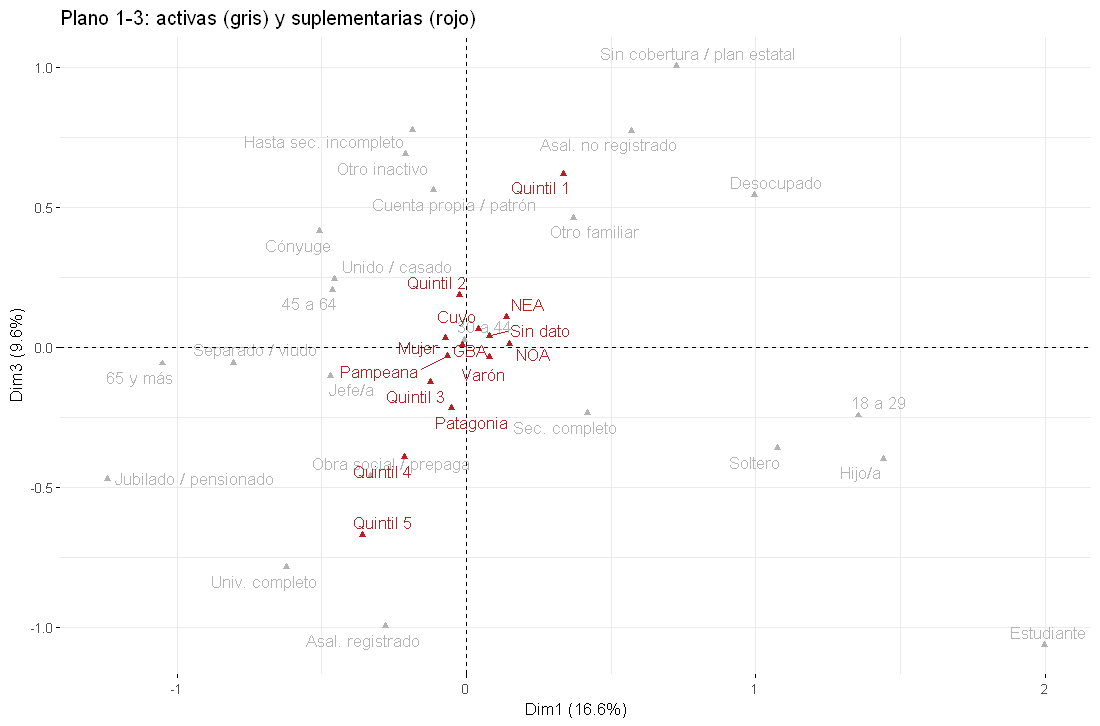

In [35]:
options(repr.plot.height = 6.6)
fviz_mca_var(res_mca, choice = "var.cat", axes = c(1, 3), repel = TRUE,
             col.var = "gray70", col.quali.sup = "firebrick",
             title = "Plano 1-3: activas (gris) y suplementarias (rojo)")

> 💡 **Lectura (el caso).** El **ingreso** no participa del MCA y, sin embargo, los quintiles se ordenan casi perfectamente sobre la Dim 3: quintil 1 en +0,62, quintil 5 en −0,67, y los del medio en orden. Es la **validación externa** de que la Dim 3 mide algo parecido a la posición socioeconómica. La **edad en años** tiene una correlación de −0,78 con la Dim 1 y de 0,39 con la Dim 2, como esperábamos. Entre las **regiones**, Patagonia queda del lado formal de la Dim 3 (−0,22) y el NEA del lado vulnerable (+0,11). El sexo casi no se mueve: Mujer está en −0,07 en la Dim 1.
>
> **Lectura (la teoría).** El v.test de "Mujer" en la Dim 1 es −13,6: **significativo** (|v| > 2), aunque su coordenada es casi cero. Con 33.000 casos, diferencias mínimas son significativas. El v.test responde "¿es distinto de cero?", no "¿es grande?". Para la magnitud, mirar la coordenada.

> ⚠️ **Atención.** Separar las variables que **describen** el fenómeno (activas) de las que queremos **usar para interpretarlo** (suplementarias) es una decisión sustantiva. Si el ingreso fuera activa, ya no podríamos usarlo para validar la Dim 3: la estaríamos construyendo con él. Además, el 38% de las personas está en hogares que no declararon ingresos completos ("Sin dato"), una categoría que como activa distorsionaría el mapa.

## 3.14 Las personas

Cada persona tiene coordenadas en las 10 dimensiones guardadas. Con 33.000 puntos el mapa es una mancha, así que coloreamos por una variable y agregamos elipses de concentración (el área que contiene a la mayoría de las personas de cada categoría).

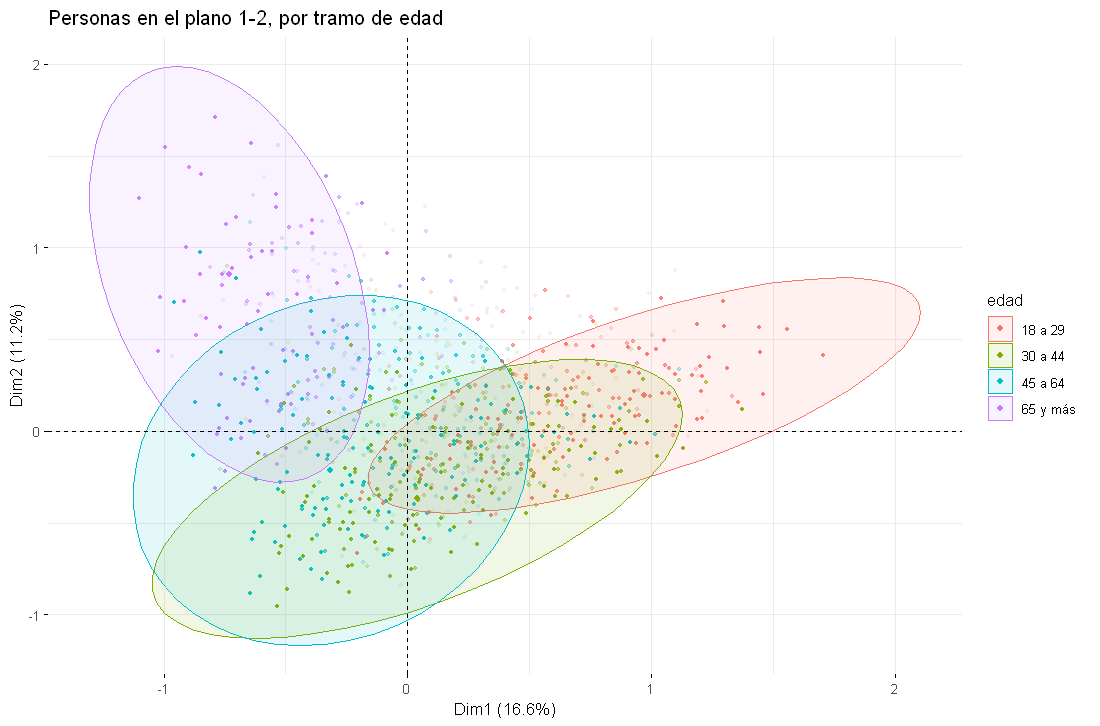

In [36]:
options(repr.plot.height = 6.6)
fviz_mca_ind(res_mca, label = "none", habillage = "edad", addEllipses = TRUE,
             ellipse.type = "norm", alpha.ind = 0.1, pointsize = 0.8,
             title = "Personas en el plano 1-2, por tramo de edad")

> 💡 **Lectura.** Los cuatro tramos de edad ocupan zonas distintas del plano 1-2: los de 18 a 29 a la derecha, los de 65 y más arriba a la izquierda y los de 30 a 64 abajo a la izquierda, superpuestos entre sí. Es la imagen del ciclo de vida de las secciones 3.6 y 3.7, ahora vista desde las personas. Muchas personas tienen **exactamente el mismo perfil** de respuestas (hay unas 1.000 combinaciones distintas para 33.000 personas) y caen en el mismo punto: el gráfico muestra muchos menos puntos de los que hay.

Las coordenadas de las personas son variables numéricas como cualquier otra. Por ejemplo, la Dim 3 se puede usar como un **índice de vulnerabilidad** (más alto, más vulnerable) y promediarlo por región, con el ponderador:

In [37]:
coords <- as_tibble(res_mca$ind$coord[, 1:5]) |>
  rename_with(\(x) str_replace(x, "Dim ", "dim")) |>
  bind_cols(select(pers, sexo, region, quintil_ipcf, PONDERA))

coords |>
  group_by(region) |>
  summarise(indice_vulnerabilidad = round(weighted.mean(dim3, PONDERA), 2)) |>
  arrange(desc(indice_vulnerabilidad))

coords |>
  group_by(quintil_ipcf) |>
  summarise(indice_vulnerabilidad = round(weighted.mean(dim3, PONDERA), 2))

region,indice_vulnerabilidad
<fct>,<dbl>
NEA,0.06
Cuyo,0.03
NOA,0.01
GBA,0.00
Pampeana,-0.02
Patagonia,-0.11


quintil_ipcf,indice_vulnerabilidad
<fct>,<dbl>
Quintil 1,0.32
Quintil 2,0.10
Quintil 3,-0.06
Quintil 4,-0.21
Quintil 5,-0.35
Sin dato,0.02


> 💡 **Lectura.** NEA (0,06), Cuyo y NOA tienen valores medios positivos (más vulnerabilidad) y la Patagonia el más negativo (−0,11). Las diferencias entre regiones son chicas comparadas con las que hay entre quintiles de ingreso, que van de 0,32 en el quintil 1 a −0,35 en el quintil 5: la región explica poco de la posición en esta dimensión. Son los mismos números que las coordenadas de las suplementarias de la sección 3.13, multiplicados por $\sqrt{\lambda_3} = 0{,}52$ (la fórmula de baricentro). La ventaja de tenerlos como un índice por persona es que se puede usar en una regresión o un gráfico como cualquier variable.

# Parte 4. k-means: la teoría

El MCA nos dio un **mapa**: cada persona tiene coordenadas numéricas. Ahora queremos **grupos**: conjuntos de personas cercanas entre sí en ese mapa y lejanas de las de otros grupos. Este tipo de técnica se llama *clustering* (o análisis de conglomerados). k-means es el algoritmo más usado.

## 4.1 Qué busca k-means

Dado un número de grupos $k$ elegido de antemano, k-means busca la partición de las $n$ observaciones en $k$ grupos $C_1, \dots, C_k$ que minimiza la **suma de cuadrados dentro de los grupos** (WSS, por *within sum of squares*):

$$\text{WSS} = \sum_{g=1}^{k} \sum_{i \in C_g} \lVert x_i - \mu_g \rVert^2$$

donde $\mu_g$ es el **centro** (la media) del grupo $g$ y $\lVert x_i - \mu_g \rVert^2$ es la distancia euclidea al cuadrado de la observación $i$ a ese centro. En palabras: grupos lo más **compactos** posible.

La variabilidad total de los datos (TSS, la suma de las distancias al cuadrado de cada punto a la media general) se reparte en dos partes:

$$\underbrace{\text{TSS}}_{\text{total}} = \underbrace{\text{WSS}}_{\text{dentro de los grupos}} + \underbrace{\text{BSS}}_{\text{entre los grupos}}$$

Como TSS no depende de la partición, minimizar WSS es lo mismo que maximizar BSS: grupos compactos por dentro y separados entre sí. El cociente **BSS / TSS** (de 0 a 1) se lee como un $R^2$: qué parte de la variabilidad queda "explicada" por los grupos.

## 4.2 El algoritmo, paso a paso

Probar todas las particiones posibles es imposible (con 33.000 personas y 5 grupos hay más particiones que átomos en el universo). k-means usa el **algoritmo de Lloyd**, que repite dos pasos:

1. **Inicio**: elegir $k$ centros (por ejemplo, $k$ observaciones al azar).
2. **Asignar**: cada observación va al grupo del centro más cercano.
3. **Actualizar**: cada centro pasa a ser la media de las observaciones de su grupo.
4. Repetir 2 y 3 hasta que ninguna observación cambie de grupo.

Cada paso no puede aumentar la WSS, así que el algoritmo siempre termina. Lo programamos a mano con datos simulados: tres nubes de puntos y tres centros iniciales mal elegidos a propósito (todos en la misma zona).

In [38]:
set.seed(3)
sim <- tibble(x = c(rnorm(60, 0, 0.8), rnorm(60, 4, 0.8), rnorm(60, 2, 0.8)),
              y = c(rnorm(60, 0, 0.8), rnorm(60, 0, 0.8), rnorm(60, 3.5, 0.8)))

centros <- tibble(x = c(-1, -0.5, 0.5), y = c(-1, 0.8, -0.5), grupo = factor(1:3))
pasos_puntos  <- list()
pasos_centros <- list()

for (iter in 0:5) {
  # Asignar: distancia de cada punto a cada centro, y el más cercano
  d <- sapply(1:3, \(g) (sim$x - centros$x[g])^2 + (sim$y - centros$y[g])^2)
  sim$grupo <- factor(apply(d, 1, which.min), levels = 1:3)
  wss <- sum(apply(d, 1, min))

  pasos_puntos[[iter + 1]]  <- mutate(sim, paso = paste0("Iteración ", iter, "\nWSS = ", round(wss)))
  pasos_centros[[iter + 1]] <- mutate(centros, paso = paste0("Iteración ", iter, "\nWSS = ", round(wss)))

  # Actualizar: cada centro pasa a ser la media de su grupo
  centros <- sim |> group_by(grupo) |> summarise(x = mean(x), y = mean(y)) |>
    complete(grupo = factor(1:3)) |>
    mutate(x = coalesce(x, centros$x), y = coalesce(y, centros$y))
}

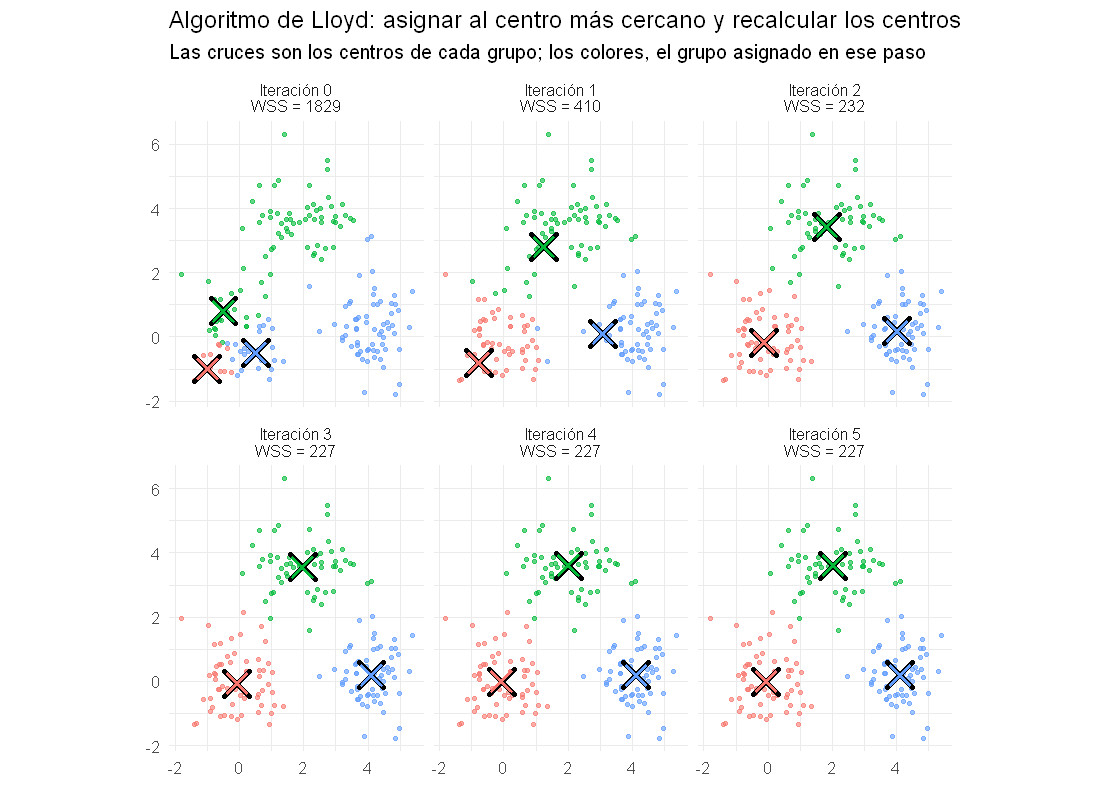

In [39]:
options(repr.plot.height = 7.15)
ggplot(bind_rows(pasos_puntos), aes(x, y, color = grupo)) +
  geom_point(alpha = 0.6, size = 1.3) +
  geom_point(data = bind_rows(pasos_centros), shape = 4, size = 6, stroke = 2.5, color = "black") +
  geom_point(data = bind_rows(pasos_centros), shape = 4, size = 5, stroke = 1.5) +
  facet_wrap(~paso, ncol = 3) +
  coord_equal() +
  guides(color = "none") +
  labs(title = "Algoritmo de Lloyd: asignar al centro más cercano y recalcular los centros",
       subtitle = "Las cruces son los centros de cada grupo; los colores, el grupo asignado en ese paso",
       x = NULL, y = NULL)

> 💡 **Lectura.** En la iteración 0, los tres centros están juntos abajo a la izquierda: el centro azul se queda con la nube de la derecha y parte de la de abajo a la izquierda, y el verde con la de arriba; la WSS es 1.829. En cada paso los centros "viajan" hacia el medio de sus puntos y la WSS baja: 410, 232, 227. Desde la iteración 3 cada centro está en el medio de una nube, los grupos dejan de cambiar y la WSS queda en 227. `kmeans()` hace exactamente esto (con una versión más eficiente del algoritmo, la de Hartigan-Wong).

In [40]:
set.seed(3)
km_sim <- kmeans(sim[, c("x", "y")], centers = 3, nstart = 10)
km_sim$centers                          # centros finales
km_sim$size                             # observaciones por grupo
km_sim$betweenss / km_sim$totss         # BSS / TSS

,x,y
1,-0.06933825,-0.00228135
2,2.01772413,3.60712421
3,4.10717290,0.19331348


[1] 61 58 61

[1] 0.817906

> 💡 **Lectura.** Los centros quedan cerca de los valores con los que simulamos las nubes, (0, 0), (4, 0) y (2; 3,5), con 58 a 61 puntos por grupo (algunos puntos de los bordes quedan más cerca de la nube vecina). BSS / TSS = 0,82: el 82% de la variabilidad de los puntos se debe a que pertenecen a nubes distintas.

## 4.3 Mínimos locales: por qué se usa nstart

Lloyd garantiza que la WSS baja en cada paso, pero no que llegue al **mínimo global**: puede quedar atrapado en una partición que no se puede mejorar moviendo un punto por vez, aunque exista otra mejor. El resultado depende de los centros iniciales.

La solución es correr el algoritmo muchas veces desde inicios al azar distintos y quedarse con la corrida de menor WSS. Eso hace el argumento **`nstart`** de `kmeans()`. Con datos reales conviene usar `nstart` = 25 o más. En la Parte 5 vemos qué pasa con `nstart = 1` en la EPH.

## 4.4 ¿Cuántos grupos?

k-means necesita que le digamos $k$. Hay dos herramientas habituales, y ninguna da "la respuesta":

**Método del codo.** Se grafica la WSS para $k = 1, 2, \dots$. La WSS siempre baja al agregar grupos (con $k = n$ es cero). Se busca el punto donde deja de bajar mucho: el "codo".

**Silueta.** Para cada observación $i$ se calcula

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}}$$

donde $a(i)$ es la distancia promedio de $i$ a los **otros miembros de su grupo** y $b(i)$ es la distancia promedio a los miembros del **grupo vecino más cercano**. $s(i)$ va de −1 a 1: cerca de 1, la observación está bien metida en su grupo; cerca de 0, está en la frontera entre dos; negativo, probablemente está en el grupo equivocado. Se elige el $k$ con mayor silueta promedio. Como valores de referencia, por encima de 0,5 la estructura de grupos es clara; entre 0,25 y 0,5, débil.

> ⚠️ **Atención.** Además de los indicadores, el criterio **sustantivo** importa: ¿los grupos se pueden describir y nombrar? ¿Sirven para la pregunta? Con datos reales es común que el codo no sea nítido y que la silueta sea parecida para varios $k$. En ese caso, cualquiera de esos $k$ es defendible y hay que justificar la elección.

## 4.5 ¿Por qué k-means sobre el MCA y no sobre las categorías?

k-means usa la **distancia euclidea** y calcula **medias**. Con variables categóricas no se puede usar directamente. Hay tres razones para correrlo sobre las coordenadas del MCA:

1. **Las coordenadas son números**, con los que tiene sentido calcular medias y distancias.
2. **La distancia euclidea entre dos personas en el espacio completo del MCA es exactamente la distancia chi-cuadrado** de la sección 2.2. Agrupar en el mapa del MCA es agrupar personas que comparten categorías, dándoles más peso a las categorías poco frecuentes.
3. **Quedarse con las primeras dimensiones filtra ruido**: las últimas dimensiones tienen poca inercia y reflejan, sobre todo, la codificación 0/1 y combinaciones poco frecuentes.

Comprobamos el punto 2 con el ejemplo de juguete. Calculamos la matriz de distancias chi-cuadrado entre las 8 personas a mano y la comparamos con la distancia euclidea entre sus coordenadas en **todas** las dimensiones del MCA:

In [41]:
d_chi2 <- outer(1:8, 1:8, Vectorize(dist_chi2))                 # a mano, fórmula de 2.2
d_mca  <- as.matrix(dist(mca_jug$ind$coord))^2                  # euclidea en el MCA (4 dimensiones)
all.equal(d_chi2, d_mca, check.attributes = FALSE)
round(d_mca[1:4, 1:4], 2)

[1] TRUE

,Persona 1,Persona 2,Persona 3,Persona 4
Persona 1,0.00,1.33,4.53,0.00
Persona 2,1.33,0.00,3.20,1.33
Persona 3,4.53,3.20,0.00,4.53
Persona 4,0.00,1.33,4.53,0.00


> 💡 **Lectura.** `all.equal()` devuelve `TRUE`: las dos matrices son iguales. La distancia entre las personas 1 y 2 es 1,33 y entre la 2 y la 3 es 3,2, como habíamos calculado a mano. Correr k-means sobre las coordenadas del MCA es, entonces, agrupar con la distancia chi-cuadrado.

> ⚠️ **Atención.** Las coordenadas del MCA **no se estandarizan** antes del k-means. Cada dimensión tiene una varianza igual a su autovalor, y queremos que las dimensiones que resumen más inercia pesen más en la distancia. Si se estandarizaran, la Dim 5 pesaría lo mismo que la Dim 1.

# Parte 5. MCA + k-means con la EPH

## 5.1 Los datos para el k-means

Usamos las coordenadas de las personas en las **5 primeras dimensiones**: suman el 51% de la inercia cruda (casi el 100% con Benzécri) y son las que pudimos interpretar en la Parte 3. En la Parte 6 vemos qué pasa con más o menos dimensiones.

In [42]:
ncp_km <- 5
X <- res_mca$ind$coord[, 1:ncp_km]
head(round(X, 2))
round(apply(X, 2, var), 3)     # varianza de cada dimensión: ≈ su autovalor

,Dim 1,Dim 2,Dim 3,Dim 4,Dim 5
1,-0.54,-0.96,-0.50,0.35,0.46
2,-0.37,-0.13,0.11,0.22,-0.46
3,1.45,0.43,-0.88,0.55,-0.53
4,-0.01,-0.24,-0.62,-0.37,-0.37
5,-0.14,0.66,-0.17,0.35,0.08
6,-0.43,0.17,-0.03,-0.82,-0.82


Dim 1 Dim 2 Dim 3 Dim 4 Dim 5 
0.504 0.323 0.264 0.213 0.176

> 💡 **Lectura.** Cada fila es una persona y cada columna, su posición en una dimensión. Las varianzas (0,50; 0,32; 0,26; 0,21; 0,18) bajan de la Dim 1 a la Dim 5, igual que los autovalores (0,47; 0,32; 0,27; 0,21; 0,18). No son idénticas porque el MCA pondera con `PONDERA` y `var()` no. Así, la Dim 1 pesa más que la Dim 5 en la distancia, como corresponde.

## 5.2 nstart en la práctica

Corremos k-means con $k = 5$ cuarenta veces con `nstart = 1` y comparamos la WSS de cada corrida con la mejor solución, obtenida con `nstart = 50`:

In [43]:
set.seed(2026)
mejor <- kmeans(X, centers = 5, nstart = 50, iter.max = 50)
wss_un_inicio <- map_dbl(1:40, \(i) kmeans(X, centers = 5, nstart = 1, iter.max = 50)$tot.withinss)

mean(wss_un_inicio > mejor$tot.withinss * 1.001)    # proporción de corridas peores que la mejor
round(range(wss_un_inicio / mejor$tot.withinss), 3)  # cuánto peores, como cociente

[1] 0.8

[1] 1.000 1.099

> 💡 **Lectura.** El 80% de las corridas con un solo inicio termina en una solución **peor** que la mejor, con hasta un 10% más de WSS. Si corremos `kmeans()` sin `nstart`, el resultado depende de la suerte. Con `nstart = 50`, el algoritmo prueba 50 inicios y se queda con el mejor.

## 5.3 Elegir k: el codo

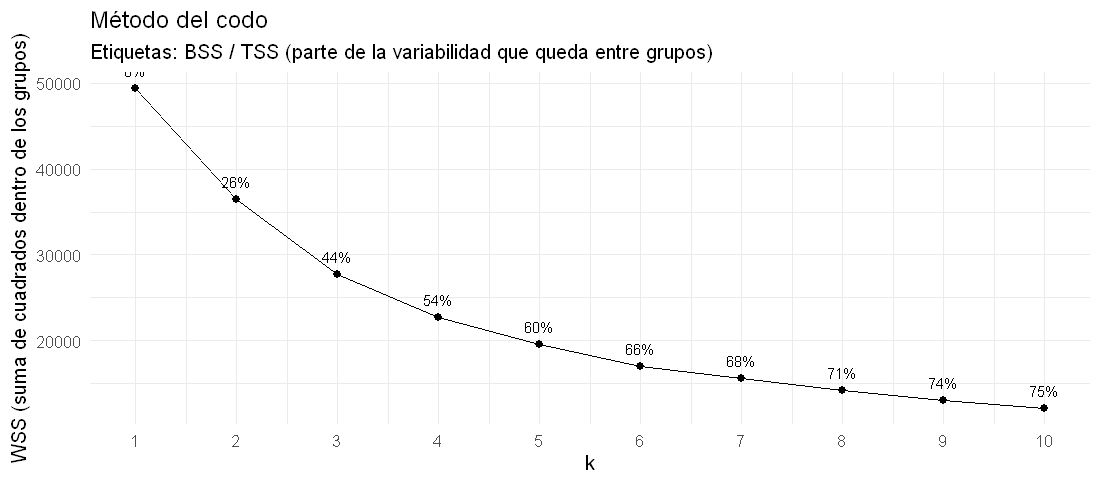

In [44]:
options(repr.plot.height = 4.4)
set.seed(2026)
wss <- map_dbl(1:10, \(k) kmeans(X, centers = k, nstart = 25, iter.max = 50)$tot.withinss)

tibble(k = 1:10, wss, bss_tss = 1 - wss / wss[1]) |>
  ggplot(aes(k, wss)) +
  geom_line() + geom_point(size = 2) +
  geom_text(aes(label = scales::percent(bss_tss, accuracy = 1)), vjust = -1, size = 3.5) +
  scale_x_continuous(breaks = 1:10) +
  labs(title = "Método del codo",
       subtitle = "Etiquetas: BSS / TSS (parte de la variabilidad que queda entre grupos)",
       y = "WSS (suma de cuadrados dentro de los grupos)")

> 💡 **Lectura.** La WSS baja rápido hasta $k = 4$ o 5 y después más despacio, pero no hay un codo nítido. Con $k = 5$ los grupos explican el 60% de la variabilidad (BSS / TSS = 0,60); pasar a $k = 6$ suma 5 puntos más, y a $k = 7$, 3 más.

## 5.4 Elegir k: la silueta

La silueta necesita **todas** las distancias entre pares de observaciones: con 33.000 personas son unos 550 millones, que no entran en memoria. La calculamos sobre una muestra al azar de 4.000.

2     3     4     5     6     7     8     9    10 
0.270 0.303 0.305 0.293 0.299 0.296 0.301 0.300 0.295

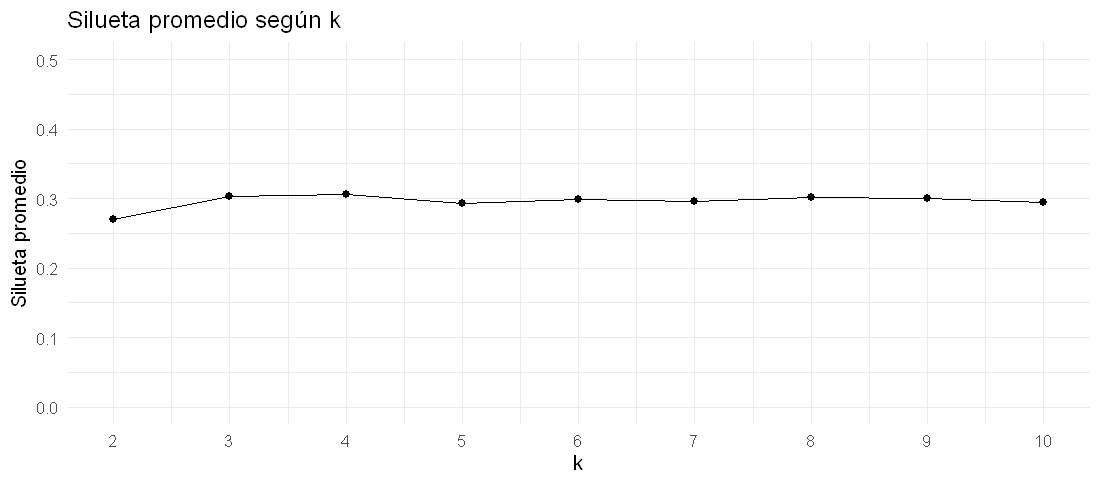

In [45]:
options(repr.plot.height = 4.4)
set.seed(2026)
muestra <- sample(nrow(X), 4000)
d_muestra <- dist(X[muestra, ])

silueta <- map_dbl(2:10, \(k) {
  grupos <- kmeans(X[muestra, ], centers = k, nstart = 25, iter.max = 50)$cluster
  mean(silhouette(grupos, d_muestra)[, "sil_width"])
})

round(setNames(silueta, 2:10), 3)

tibble(k = 2:10, silueta) |>
  ggplot(aes(k, silueta)) +
  geom_line() + geom_point(size = 2) +
  scale_x_continuous(breaks = 2:10) +
  scale_y_continuous(limits = c(0, 0.5)) +
  labs(title = "Silueta promedio según k", y = "Silueta promedio")

> 💡 **Lectura (el caso).** La silueta es casi plana: queda entre 0,27 y 0,31 para cualquier $k$ entre 2 y 10 (el máximo, apenas, en $k$ = 3 o 4). Según la regla de referencia, es una estructura de grupos **débil**. No hay un $k$ que se destaque.
>
> **Lectura (la teoría).** Es lo esperable con variables categóricas sobre personas: la población no está formada por "nubes" separadas, sino por un **continuo** de situaciones. k-means igual parte ese continuo en zonas, y esas zonas pueden ser muy útiles para describir, pero no son "tipos naturales" de personas. Elegimos **$k = 5$** porque da grupos de tamaño parecido y fáciles de nombrar (lo vemos enseguida). Otro $k$ no estaría "mal": sería otra resolución de la misma foto (sección 6.3).

## 5.5 El k-means final

In [46]:
k <- 5
set.seed(2026)
km <- kmeans(X, centers = k, nstart = 50, iter.max = 50)

km$size                      # personas por grupo (en la muestra)
km$betweenss / km$totss      # BSS / TSS
round(km$centers, 2)         # centros, en coordenadas del MCA

[1] 5586 8032 6299 6478 6980

[1] 0.6030669

,Dim 1,Dim 2,Dim 3,Dim 4,Dim 5
1,-0.76,0.97,-0.08,0.11,0.14
2,-0.25,-0.27,-0.43,-0.32,-0.10
3,-0.40,-0.47,0.13,0.54,-0.06
4,1.15,0.26,-0.23,0.17,-0.12
5,0.23,-0.09,0.60,-0.32,0.08


> 💡 **Lectura.** Cinco grupos de entre 5.500 y 8.000 personas de la muestra; BSS / TSS = 0,60. Los centros ya dan pistas si se leen con las dimensiones de la Parte 3: un grupo tiene la Dim 2 muy alta (vejez), otro la Dim 1 muy alta (jóvenes), otro la Dim 3 alta (vulnerabilidad), otro la Dim 4 alta (cónyuges) y otro tiene la Dim 3 negativa (formalidad). Pero los centros en coordenadas del MCA no se pueden comunicar en un informe. Para describir los grupos hay que volver a las **categorías originales**.

> ⚠️ **Atención.** Los **números** de los grupos (1 a 5) son arbitrarios: con otra semilla, el grupo 1 puede pasar a ser el 4. No tienen orden ni significado. Además, `kmeans()` no acepta ponderadores: trata a todas las personas de la muestra por igual. El ponderador lo usamos para **describir** los grupos (sus tamaños y perfiles en la población). Con una muestra grande y bien distribuida, la diferencia es menor.

In [47]:
pers <- pers |> mutate(grupo = factor(km$cluster))

pers |>                                  # peso de cada grupo en la población
  count(grupo, wt = PONDERA) |>
  mutate(pct = round(100 * n / sum(n), 1))

grupo,n,pct
<fct>,<dbl>,<dbl>
1,3268043,15.0
2,5369951,24.6
3,4395867,20.1
4,3988597,18.3
5,4795831,22.0


## 5.6 Quién está en cada grupo: perfiles

El **perfil** de un grupo es el porcentaje (ponderado) de sus integrantes que tiene cada categoría. Lo calculamos para las variables activas y para las suplementarias.

In [48]:
perfil <- pers |>
  select(grupo, condicion:quintil_ipcf, PONDERA) |>
  pivot_longer(condicion:quintil_ipcf, names_to = "variable", values_to = "categoria") |>
  count(grupo, variable, categoria, wt = PONDERA) |>
  group_by(grupo, variable) |>
  mutate(pct = round(100 * n / sum(n))) |>
  ungroup()

perfil_ancho <- perfil |>
  select(-n) |>
  pivot_wider(names_from = grupo, values_from = pct, values_fill = 0, names_prefix = "G")
perfil_ancho

variable,categoria,G1,G2,G3,G4,G5
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
condicion,Asal. no registrado,3,5,7,21,44
condicion,Asal. registrado,2,72,35,14,0
condicion,Cuenta propia / patrón,5,20,15,8,32
condicion,Desocupado,1,1,2,12,10
condicion,Estudiante,0,0,1,29,0
condicion,Jubilado / pensionado,59,2,2,0,0
condicion,Otro inactivo,31,1,38,16,14
edad,18 a 29,0,7,8,93,16
edad,30 a 44,0,42,36,6,48


Para ponerle nombre a cada grupo **no** escribimos "grupo 1 = jubilados" a mano: si se cambia la semilla, los números cambian y el nombre quedaría mal. Buscamos el grupo con más peso de la categoría que lo define:

In [49]:
pct_de <- function(var, cat) {
  perfil |> filter(variable == var, categoria == cat) |> select(grupo, pct) |> deframe()
}
grupo_con_mas <- function(var, cat) names(which.max(pct_de(var, cat)))

nombres <- c(
  "Adultos mayores"                  = grupo_con_mas("edad", "65 y más"),
  "Jóvenes que viven con sus padres" = grupo_con_mas("parentesco", "Hijo/a"),
  "Cónyuges"                         = grupo_con_mas("parentesco", "Cónyuge"),
  "Trabajadores formales"            = grupo_con_mas("condicion", "Asal. registrado"),
  "Informales sin cobertura"         = grupo_con_mas("salud", "Sin cobertura / plan estatal")
)
nombres                       # chequear que cada grupo aparezca UNA sola vez
stopifnot(!anyDuplicated(nombres))

pers <- pers |> mutate(grupo_nom = factor(grupo, levels = nombres, labels = names(nombres)))
perfil <- perfil |> mutate(grupo_nom = factor(grupo, levels = nombres, labels = names(nombres)))
count(pers, grupo_nom, wt = PONDERA) |> mutate(pct = round(100 * n / sum(n), 1))

Adultos mayores Jóvenes que viven con sus padres 
                             "1"                              "4" 
                        Cónyuges            Trabajadores formales 
                             "3"                              "2" 
        Informales sin cobertura 
                             "5"

grupo_nom,n,pct
<fct>,<dbl>,<dbl>
Adultos mayores,3268043,15.0
Jóvenes que viven con sus padres,3988597,18.3
Cónyuges,4395867,20.1
Trabajadores formales,5369951,24.6
Informales sin cobertura,4795831,22.0


> 💡 **Lectura.** Los cinco grupos, con su peso en la población de 18 años y más y lo que los define en la tabla de perfiles:
>
> - **Adultos mayores** (15%): el 94% tiene 65 años o más y el 59% es jubilado. Son jefes de hogar (77%), muchos separados o viudos (52%), con cobertura de salud casi universal (99%). Seis de cada diez son mujeres.
> - **Jóvenes que viven con sus padres** (18%): el 93% tiene de 18 a 29 años, el 96% es soltero y el 86% es hijo/a del jefe. Mezcla estudiantes (29%), asalariados no registrados (21%) y desocupados (12%, la tasa más alta). La mitad no tiene cobertura.
> - **Cónyuges** (20%): el 93% es cónyuge del jefe y el 100% está unido o casado. El 72% son mujeres. El 38% es "otro inactivo" (en su mayoría, tareas del hogar) y el 35% asalariado registrado.
> - **Trabajadores formales** (25%): el 72% es asalariado registrado y el 20% cuentapropista, con obra social (99%). Jefes de hogar (84%) de 30 a 64 años; el grupo más educado (40% universitario) y el más presente en el quintil 5.
> - **Informales sin cobertura** (22%): el 90% no tiene obra social. Asalariados no registrados (44%) y cuentapropistas (32%) de 30 a 64 años, con educación baja (57% sin secundario completo). Es el grupo más concentrado en el quintil 1 (28%).

> ⚠️ **Atención.** El ingreso, el sexo y la región **no** participaron en la formación de los grupos y, sin embargo, los grupos difieren mucho en ingreso y en sexo. Eso es información: dice que los grupos capturan algo relacionado con la posición socioeconómica y con roles de género en el hogar. La región, en cambio, casi no cambia entre grupos (GBA está entre el 52% y el 56% en todos): los mismos cinco tipos aparecen en todo el país, con pesos parecidos.

## 5.7 El perfil en un gráfico

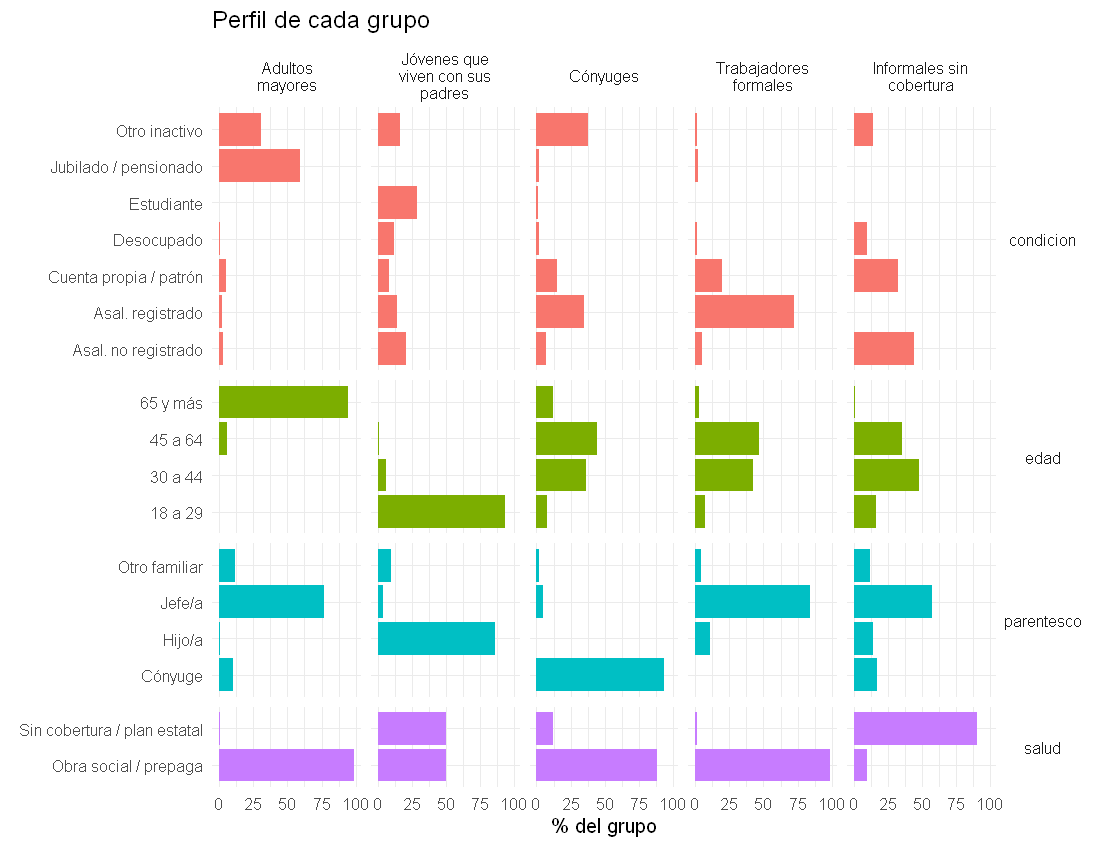

In [50]:
options(repr.plot.height = 7.7)
perfil |>
  filter(variable %in% c("condicion", "salud", "edad", "parentesco")) |>
  ggplot(aes(x = pct, y = categoria, fill = variable)) +
  geom_col(show.legend = FALSE) +
  facet_grid(variable ~ grupo_nom, scales = "free_y", space = "free_y",
             labeller = labeller(grupo_nom = label_wrap_gen(15))) +
  labs(x = "% del grupo", y = NULL, title = "Perfil de cada grupo") +
  theme(strip.text.y = element_text(angle = 0))

> 💡 **Lectura.** Cada columna es un grupo y cada fila, una variable. En cada grupo hay una o dos barras que dominan: es la "firma" del grupo. "Adultos mayores" se define por la edad, "Jóvenes" y "Cónyuges" por el parentesco, "Formales" por la condición y "Informales" por la salud. Los grupos combinan las tres dimensiones del MCA: el ciclo de vida (Dim 1 y 2), la formalidad (Dim 3) y la posición en el hogar (Dim 4).

## 5.8 Descripción automática: catdes()

`catdes()` (de FactoMineR) compara, para cada grupo, la frecuencia de cada categoría **dentro del grupo** con su frecuencia **en toda la base**, y ordena las categorías por un test (v.test). Las columnas son:

| Columna | Qué es | Ejemplo de lectura |
|:--|:--|:--|
| `Cla/Mod` | % de las personas con la categoría que están en el grupo | "El X% de los jubilados está en este grupo" |
| `Mod/Cla` | % del grupo que tiene la categoría | "El X% del grupo es jubilado" |
| `Global` | % de la categoría en toda la base | "El X% de la población es jubilada" |

Una categoría **caracteriza** al grupo cuando `Mod/Cla` es mucho mayor que `Global`.

In [51]:
desc_grupos <- catdes(pers |> select(grupo_nom, condicion:quintil_ipcf, edad_num) |> as.data.frame(),
                      num.var = 1, row.w = peso)

for (g in names(nombres)) {
  cat("\n====", g, "====\n")
  print(round(desc_grupos$category[[g]][1:6, 1:3], 1))
}


==== Adultos mayores ====
                                Cla/Mod Mod/Cla Global
parentesco=Jefe/a                  24.8    77.1   46.6
est_civil=Separado / viudo         53.4    52.4   14.7
edad=65 y más                      80.4    93.5   17.4
salud=Obra social / prepaga        21.6    98.9   68.6
condicion=Jubilado / pensionado    91.2    59.0    9.7
educacion=Hasta sec. incompleto    24.3    55.7   34.3

==== Jóvenes que viven con sus padres ====
                                   Cla/Mod Mod/Cla Global
parentesco=Hijo/a                     72.1    85.9   21.8
est_civil=Soltero                     53.0    96.0   33.1
edad=18 a 29                          71.2    92.6   23.8
educacion=Sec. completo               29.7    74.0   45.5
condicion=Estudiante                  96.5    29.3    5.5
salud=Sin cobertura / plan estatal    28.9    49.6   31.4

==== Cónyuges ====
                            Cla/Mod Mod/Cla Global
parentesco=Cónyuge             77.4    92.6   24.1
est_civil=Unido 

> 💡 **Lectura.** Las seis categorías más sobrerrepresentadas de cada grupo confirman los nombres. En "Informales sin cobertura", por ejemplo, sin cobertura / plan estatal es el 90% del grupo (`Mod/Cla`) frente a un 31% en la población (`Global`), y el 63% de todas las personas sin cobertura está en este grupo (`Cla/Mod`). Aparecen también categorías suplementarias, como el quintil 1 (28% del grupo frente a 14% en la población) o "Mujer" en los cónyuges (72% frente a 52%). El 91% de los jubilados está en "Adultos mayores".
>
> El orden de las filas sigue el v.test, pero con 33.000 casos varios v.test son infinitos (p-valor redondeado a 0) y el orden entre ellos no significa nada. Por eso mostramos solo las tres primeras columnas y comparamos `Mod/Cla` con `Global`. Como el ponderador está reescalado (sección 3.3), los tests usan el tamaño real de la muestra.

## 5.9 Los grupos en el mapa del MCA

Graficamos una muestra de 5.000 personas en dos planos del MCA, coloreadas por grupo y con el centro de cada grupo. Como muchas personas tienen exactamente el mismo perfil, `geom_jitter()` las separa un poco para que se vea cuántas hay en cada punto.

In [52]:
coords <- coords |> mutate(grupo = pers$grupo_nom)
centros_grupos <- coords |> group_by(grupo) |> summarise(across(dim1:dim5, mean))

graf_plano <- function(ejes) {
  set.seed(2026)
  ggplot(slice_sample(coords, n = 5000), aes(.data[[ejes[1]]], .data[[ejes[2]]], color = grupo)) +
    geom_jitter(width = 0.05, height = 0.05, alpha = 0.3, size = 0.8) +
    geom_label(data = centros_grupos, aes(label = str_wrap(grupo, 15)), size = 3, show.legend = FALSE) +
    geom_hline(yintercept = 0, linetype = "dashed") +
    geom_vline(xintercept = 0, linetype = "dashed") +
    guides(color = "none") +
    labs(title = paste("Grupos en el plano", ejes[1], "-", ejes[2]))
}

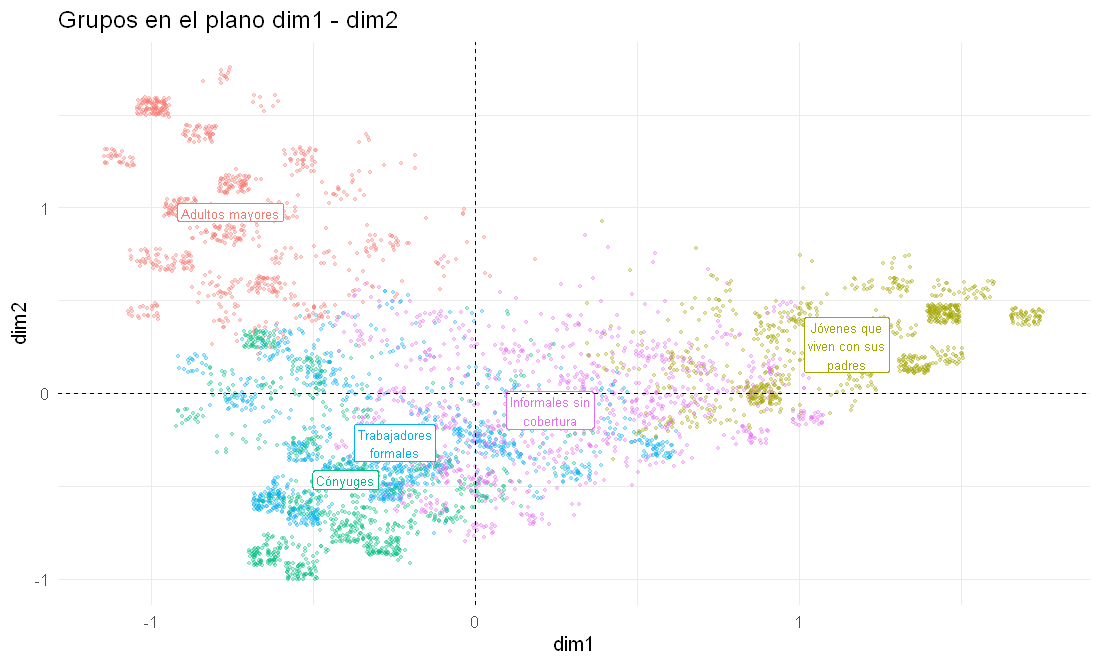

In [53]:
options(repr.plot.height = 6.05)
graf_plano(c("dim1", "dim2"))

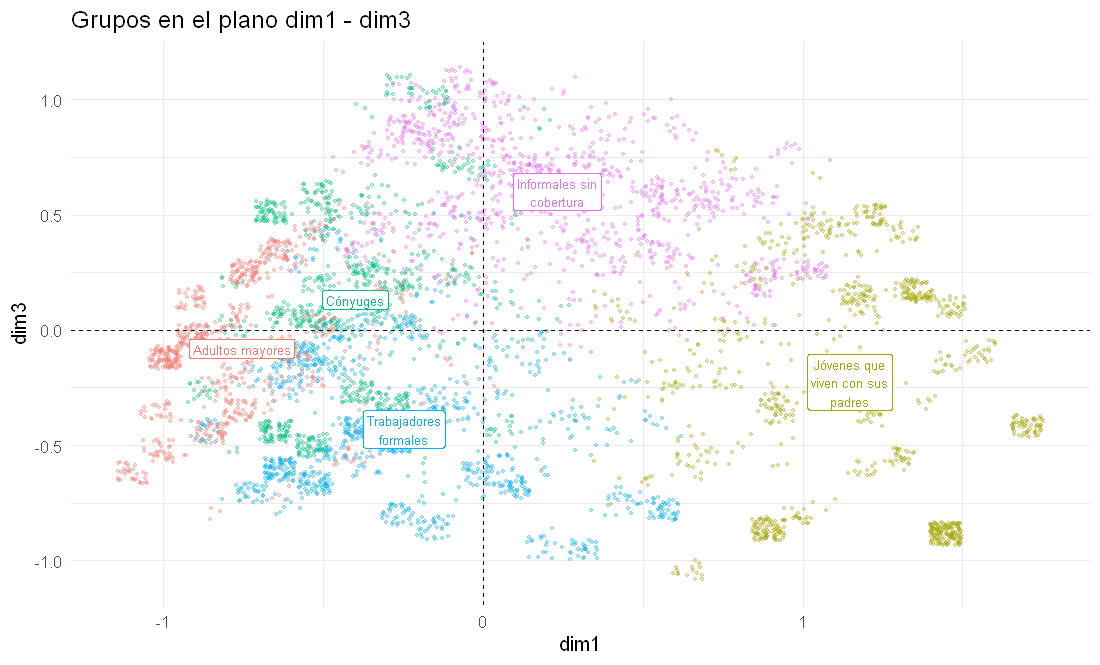

In [54]:
options(repr.plot.height = 6.05)
graf_plano(c("dim1", "dim3"))

> 💡 **Lectura.** En el plano 1-2 se separan con claridad los jóvenes (a la derecha) y los adultos mayores (arriba a la izquierda). Formales, informales y cónyuges quedan superpuestos en ese plano: los tres son adultos de 30 a 64. En el plano 1-3, formales e informales se separan sobre la Dim 3. Los cónyuges se distinguen en la Dim 4, que no está en ninguno de los dos gráficos. Por eso usamos más de dos dimensiones para el k-means: un plano muestra solo una parte. Los grupos no son "islas": hay personas en la frontera entre dos.

Otra forma de verlo: rehacer el MCA agregando el grupo como **variable suplementaria**. Así cada grupo queda ubicado en el mismo mapa que las categorías (en el baricentro de sus integrantes).

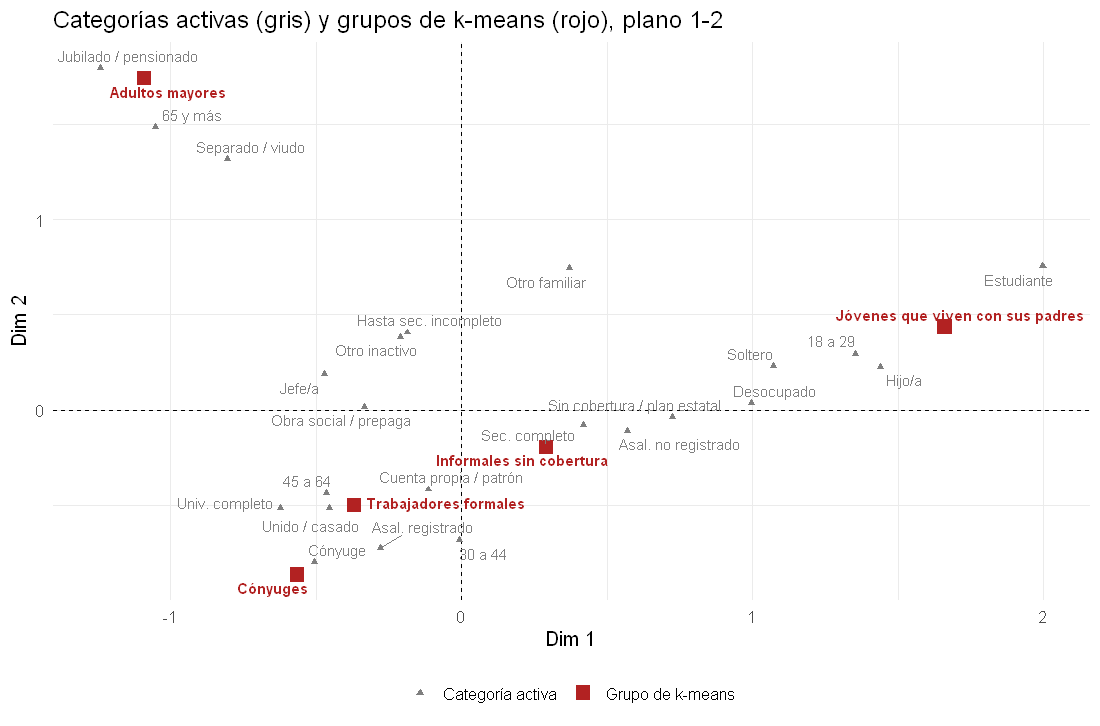

In [55]:
options(repr.plot.height = 6.6)
res_mca_g <- MCA(pers |> select(condicion:parentesco, grupo_nom) |> as.data.frame(),
                 quali.sup = 7, row.w = peso, graph = FALSE)

puntos_mapa <- bind_rows(
  tibble(etiqueta = rownames(res_mca_g$var$coord), tipo = "Categoría activa",
         dim1 = res_mca_g$var$coord[, 1], dim2 = res_mca_g$var$coord[, 2]),
  tibble(etiqueta = rownames(res_mca_g$quali.sup$coord), tipo = "Grupo de k-means",
         dim1 = res_mca_g$quali.sup$coord[, 1], dim2 = res_mca_g$quali.sup$coord[, 2]))

ggplot(puntos_mapa, aes(dim1, dim2, color = tipo)) +
  geom_hline(yintercept = 0, linetype = "dashed") +
  geom_vline(xintercept = 0, linetype = "dashed") +
  geom_point(aes(size = tipo, shape = tipo)) +
  ggrepel::geom_text_repel(aes(label = etiqueta, fontface = if_else(tipo == "Grupo de k-means", "bold", "plain")),
                           size = 3.5, max.overlaps = 30, show.legend = FALSE) +
  scale_color_manual(values = c("gray50", "firebrick")) +
  scale_size_manual(values = c(1.5, 4)) +
  scale_shape_manual(values = c(17, 15)) +
  labs(title = "Categorías activas (gris) y grupos de k-means (rojo), plano 1-2",
       x = "Dim 1", y = "Dim 2", color = NULL, size = NULL, shape = NULL) +
  theme(legend.position = "bottom")

> 💡 **Lectura.** Cada grupo (en rojo) queda junto a las categorías que lo definen: "Adultos mayores" al lado de jubilado y 65 y más; "Jóvenes" al lado de estudiante, hijo/a y 18 a 29; "Cónyuges" junto a cónyuge. "Trabajadores formales" e "Informales sin cobertura" quedan cerca del centro en este plano porque lo que los separa es la Dim 3. Es el mismo MCA de la Parte 3 (las activas son las mismas), así que las coordenadas de las categorías no cambian.

## 5.10 Guardar la tabla de perfiles

Para el informe, una tabla con los perfiles en porcentajes. `datasummary_df()` (de `modelsummary`) guarda cualquier data frame en Word.

In [56]:
tabla_perfiles <- perfil |>
  filter(variable %in% c("condicion", "educacion", "salud", "edad", "parentesco", "quintil_ipcf")) |>
  arrange(grupo_nom, variable, categoria) |>
  select(variable, categoria, grupo_nom, pct) |>
  pivot_wider(names_from = grupo_nom, values_from = pct, values_fill = 0) |>
  rename(Variable = variable, Categoría = categoria)

modelsummary::datasummary_df(tabla_perfiles, fmt = 0,
                             title = "Perfil de cada grupo (% ponderado de cada categoría dentro del grupo)",
                             output = "perfiles_grupos.docx") |>
  invisible()
tabla_perfiles

Variable,Categoría,Adultos mayores,Jóvenes que viven con sus padres,Cónyuges,Trabajadores formales,Informales sin cobertura
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
condicion,Asal. no registrado,3,21,7,5,44
condicion,Asal. registrado,2,14,35,72,0
condicion,Cuenta propia / patrón,5,8,15,20,32
condicion,Desocupado,1,12,2,1,10
condicion,Estudiante,0,29,1,0,0
condicion,Jubilado / pensionado,59,0,2,2,0
condicion,Otro inactivo,31,16,38,1,14
edad,18 a 29,0,93,8,7,16
edad,30 a 44,0,6,36,42,48


> 💡 **Lectura.** El archivo `perfiles_grupos.docx` queda en la misma carpeta que el notebook (en Colab, en el panel de archivos). Cada columna suma 100% dentro de cada variable.

# Parte 6. ¿Qué tan confiables son los grupos?

Un agrupamiento sirve si **no cambia por detalles del método**. Si los grupos se rearman por completo al cambiar la semilla o la cantidad de dimensiones, no hay que contarlos como un hallazgo.

Para comparar dos particiones de las mismas personas se usa el **índice de Rand ajustado (ARI)**. El índice de Rand mira todos los pares de personas y cuenta la proporción de pares en los que las dos particiones "coinciden" (las dos los ponen juntos, o las dos los separan). El ARI le resta lo que se esperaría por azar:

$$\text{ARI} = \frac{\text{Rand} - \text{Rand esperado por azar}}{\text{Rand máximo} - \text{Rand esperado por azar}}$$

ARI = 1: particiones idénticas (aunque los números de grupo sean distintos). ARI ≈ 0: coincidencia al azar. Como referencia, un ARI mayor a 0,8 indica particiones muy parecidas.

## 6.1 Otra semilla

In [57]:
set.seed(123)
km_b <- kmeans(X, centers = k, nstart = 50, iter.max = 50)
table(original = pers$grupo_nom, otra_semilla = km_b$cluster)
mclust::adjustedRandIndex(km$cluster, km_b$cluster)

                                  otra_semilla
original                              1    2    3    4    5
  Adultos mayores                  5574    0    0    0   12
  Jóvenes que viven con sus padres    0    0 5662   36  780
  Cónyuges                            0 6299    0    0    0
  Trabajadores formales               0    0    0 8029    3
  Informales sin cobertura            0  278    0   73 6629

[1] 0.9169883

> 💡 **Lectura.** Los números de grupo cambiaron (por eso la tabla no es diagonal), pero cada grupo original cae casi entero en un grupo nuevo: ARI = 0,92. Adultos mayores, cónyuges y formales quedan prácticamente iguales; unos 780 jóvenes pasan al grupo de los informales y unos 280 informales, al de los cónyuges. No es exactamente 1 porque la WSS tiene varias soluciones de valor muy parecido (consecuencia de la estructura débil que mostró la silueta), y con otra semilla k-means puede llegar a una vecina, que reasigna personas de la frontera. La partición es estable.

## 6.2 Otra cantidad de dimensiones

In [58]:
ari_ncp <- map_dbl(3:8, \(d) {
  set.seed(2026)
  km_d <- kmeans(res_mca$ind$coord[, 1:d], centers = k, nstart = 25, iter.max = 50)
  mclust::adjustedRandIndex(km$cluster, km_d$cluster)
})
tibble(dimensiones = 3:8, ARI = round(ari_ncp, 2))

dimensiones,ARI
<int>,<dbl>
3,0.51
4,0.92
5,1.00
6,0.86
7,0.61
8,0.54


> 💡 **Lectura.** Con 4 o 6 dimensiones los grupos se parecen mucho a los de 5 (ARI = 0,92 y 0,86). Con 3 cambian bastante (0,51): falta la Dim 4, que es la que separa a los cónyuges. Con 7 u 8 también cambian (0,61 y 0,54): las Dim 6 a 8 están construidas por pocas categorías (la Dim 6, sobre todo por "Otro familiar", con el 39% de la contribución; la Dim 7, casi solo por "Desocupado", con el 72%) y, al sumarlas, aparecen grupos alrededor de esas categorías. La elección de 5 dimensiones no es inocua: es parte de la definición de "parecido" y hay que reportarla.

## 6.3 Otro k

In [59]:
set.seed(2026)
km6 <- kmeans(X, centers = 6, nstart = 50, iter.max = 50)
table(k5 = pers$grupo_nom, k6 = km6$cluster)

                                  k6
k5                                    1    2    3    4    5    6
  Adultos mayores                   224   10    0    3    0 5349
  Jóvenes que viven con sus padres   35    7   45 2731 3660    0
  Cónyuges                           46 4228 2025    0    0    0
  Trabajadores formales            2189    0 5659   56    4  124
  Informales sin cobertura         2371 1541  117 2946    0    5

> 💡 **Lectura.** Cada fila es un grupo de $k = 5$ y muestra cómo se reparte entre los 6 grupos nuevos. "Adultos mayores" queda casi intacto (una sola celda grande en su fila). Los jóvenes y los cónyuges se parten en dos. Los informales se reparten entre tres grupos nuevos, y parte de los formales se junta con informales en un grupo nuevo. Más grupos dan más detalle, pero también grupos más difíciles de nombrar y de comunicar. Ninguna de las dos soluciones es "la verdadera": son dos resoluciones de la misma foto.

## 6.4 ¿Y sin el MCA?

¿Qué pasaría si corriéramos k-means directamente sobre la tabla disyuntiva (una columna 0/1 por categoría), sin pasar por el MCA?

In [60]:
Z_eph <- tab.disjonctif(pers |> select(condicion:parentesco) |> as.data.frame())
set.seed(2026)
km_z <- kmeans(Z_eph, centers = k, nstart = 25, iter.max = 50)
table(con_MCA = pers$grupo_nom, sin_MCA = km_z$cluster)
mclust::adjustedRandIndex(km$cluster, km_z$cluster)

                                  sin_MCA
con_MCA                               1    2    3    4    5
  Adultos mayores                   621   19   35 4897   14
  Jóvenes que viven con sus padres   35 6334   98    1   10
  Cónyuges                         5201    9  733    6  350
  Trabajadores formales              33  775   56  218 6950
  Informales sin cobertura           72  681 5746   68  413

[1] 0.711278

> 💡 **Lectura (el caso).** Las dos particiones coinciden en buena parte (ARI = 0,71): cada grupo con MCA tiene una contraparte sin MCA. Pero entre el 10% y el 20% de las personas de casi todos los grupos cae en otro. Solo el grupo de jóvenes se mantiene casi entero.
>
> **Lectura (la teoría).** La diferencia viene de la distancia. Sobre la tabla 0/1, la distancia euclidea trata igual a todas las categorías: diferir en "desocupado" pesa lo mismo que diferir en "ocupado". Sobre el MCA, la distancia es la chi-cuadrado, que pesa más las categorías poco frecuentes, y además dejamos afuera las dimensiones de "ruido". El MCA no es solo un paso técnico para tener números: **define qué significa que dos personas se parezcan**.

# Cierre

## Qué reportar en el TP si usan MCA + k-means

| Paso | Qué hay que informar |
|:--|:--|
| Variables | Cuáles son activas y cuáles suplementarias, y por qué |
| Categorías | Cómo se agruparon, con su frecuencia y un criterio **sustantivo** para cada agrupamiento |
| Ponderación | Si se usó el ponderador y cómo (en el MCA, en los perfiles) |
| MCA | % de inercia (crudo y con Benzécri) de las dimensiones que se interpretan |
| Interpretación | Un nombre para cada dimensión, justificado con las categorías de mayor contribución de cada lado |
| Suplementarias | Cómo se ubican en el mapa (coordenadas, v.test) y qué validan |
| k-means | Cuántas dimensiones del MCA se usaron, `nstart`, cómo se eligió $k$ (codo, silueta y criterio sustantivo) |
| Grupos | Tabla de perfiles en porcentajes de las categorías originales y un nombre para cada grupo |
| Robustez | Al menos una prueba de sensibilidad: otra semilla, otra cantidad de dimensiones u otro $k$, con el ARI |

## Lo que estos resultados *no* dicen

- **Los grupos no son "naturales".** La silueta de 0,3 muestra que la población es un continuo. k-means lo parte en zonas útiles para describir, pero otro $k$ u otras variables darían otras zonas.
- **Las dimensiones no son causas.** Que la Dim 3 ordene el ingreso no quiere decir que la formalidad "cause" el ingreso (ni al revés): son características que aparecen juntas.
- **El resultado depende de las decisiones previas.** Qué variables entran, cómo se agrupan las categorías y cuántas dimensiones se usan cambian los grupos tanto como el algoritmo.
- **El signo y el número son arbitrarios.** El signo de una dimensión y el número de un grupo no significan nada por sí mismos.